# Laboratorio – Ingenio Providencia

## Tarea 1. Introducción y contexto del negocio

La agroindustria de la caña representa el 19,5 % del PIB agrícola y el 12,1 % del PIB industrial del Valle del Cauca (Asocaña, datos 2023), con 13 ingenios en la región.

- **TCH** depende de las lluvias, el suelo, la variedad, la edad de cosecha, el número de cortes, el riego y la fertilización. El efecto de la lluvia no es lineal: tanto el déficit como el exceso reducen el rendimiento.
- **%Sac.Caña** depende principalmente de la maduración (madurantes, semanas de maduración), la variedad y el clima de los meses previos a la cosecha.
- En la literatura, los modelos más usados para predecir rendimiento son la regresión lineal múltiple, Random Forest y Gradient Boosting.
- Para la clasificación se usarán terciles (bajo ≤ P33,3 < medio ≤ P66,7 < alto).

El desarrollo completo está en `Docs/Taller.pdf` y en el informe.

## Tarea 2. Análisis exploratorio de datos (EDA) y preprocesamiento

En esta parte la idea es comprender cómo están estructurados los datos de los datasets que tenemos como recursos y además la calidad de los mismos.
Se analizarán los valores faltantes, las distribuciones de las variables, los posibles valores atípicos y las relaciones entre los predictores y las variables objetivo.

Se trabajará con dos datasets: HISTORICO_SUERTES.xlsx, para explorar la predicción de TCH y del porcentaje de sacarosa mediante regresión, y BD_IPSA_1940.xlsx, para preparar las variables destinadas a los modelos de clasificación.

### 2.1 Configuración inicial

Por si acaso, como uso conda en mi portátil Linux, tuve que instalar estas librerías (dependiendo de la manera en la que tengas instalado jupyter el comando puede variar): %pip install pandas numpy matplotlib seaborn openpyxl scikit-learn statsmodels


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from statsmodels.stats.outliers_influence import variance_inflation_factor

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

In [2]:
# Librerías adicionales para la Fase 2 (prueba de normalidad y VIF)
import statsmodels.api as sm
from scipy import stats

### 2.2 Carga de datos

Para cargar los datasets y mantener una estructura coherente con el repositorio, se usa una ruta relativa a la carpeta `Data`.

In [3]:
import pandas as pd
from pathlib import Path

# Carpeta donde se encuentran los datasets, Lo busca para que no tengamos problemas en el repo
ruta_datos = Path("Data")

# Cargar los archivos Excel
historico = pd.read_excel(ruta_datos / "HISTORICO_SUERTES.xlsx")
ipsa = pd.read_excel(ruta_datos / "BD_IPSA_1940.xlsx")

# Verificar que se cargaron correctamente
print("Dimensiones de HISTORICO_SUERTES:", historico.shape)
print("Dimensiones de BD_IPSA_1940:", ipsa.shape)

display(historico.head())
display(ipsa.head())

Dimensiones de HISTORICO_SUERTES: (21027, 85)
Dimensiones de BD_IPSA_1940: (2187, 21)


,Período,Hacienda,Nombre,Zona,Tenencia,Suerte,Suelo,Area Neta,Dist Km,Variedad,Cod.Estado #,Cod.Estado,F.Siembra,D.S.,Ult.Riego,Edad Ult Cos,F.Ult.Corte,Destino 1=Semilla,Cod. T.Cultivo,Cultivo,Fec.Madur.,Producto,Dosis Madurante,Semanas mad.,TonUltCorte,TCH,TCHM,Ton.Azucar,Rdto,TAH,TAHM,Sac.Caña Precosecha,Edad.Precosecha,%Sac.Caña,%Sac.Muestreadora,%ATR,KATRHM,%Fibra Caña,%AR Jugo,%ME Min,%ME Veg,%ME Tot,Brix,Pureza,Vejez,Tipo Quema,T.Corte,Cerca de,Cosechó,Num.Riegos,M3 Riego,DDUlt.Riego,Lluvias (2 Meses Ant.),Lluvias Ciclo,Lluvias 0 -3,Lluvias tres a seis,Lluvias seis a nueve,Luvias 9 -FC,%Infest.Diatrea,Fosfato Jugo,Fert.Nitrogen.,Urea 46%,MEZ,Boro Granul.,MicroZinc,NITO_XTEND,Sul.Amonio,NITRAX-S,Vinaza,Codigo Estacion,Temp. Media 0-3,Temp. Media Ciclo,Temp Max Ciclo,Temp Min Ciclo,Humedad Rel Media 0-3,Humedad Rel Media Ciclo,Oscilacion Temp Med 0-3,Oscilacion Temp Ciclo,Sum Oscilacion Temp Ciclo,Radicion Solar 0-3,Radiacion Solar Ciclo,Precipitacion 0_3,Precipitacion Ciclo,Evaporacion 0-3,Evaporacion Ciclo
0,201701,80493,LA CONCHA,IP02,51.0,002A,CANTARINA,6.00,4.3,CC85-92,5,Corte 5,2010-08-20,NaN,NaT,12.81,2017-01-02,0,1.0,Normal,2016-11-04,BONUS 250 EC REGULADOR FISIOLÓGICO,1.0,8.428571,727.19,121.198333,9.461228,86.050,11.8332,14.341666,1.119567,16.8172,NaN,13.7582,13.508,15.1653,1434.823641,16.910,0.84,0.355,10.198,10.553,15.7464,87.2241,2.735,VERDE,MECANIZADO,El Cerrito,AI08,NaN,0.0,0,258.0,1038.0,0.0,454.0,102.0,482.0,NaN,178.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,201701,81284,UKRANIA INCAUCA,IP05,81.0,039B,NaN,1.45,NaN,CC85-92,5,Corte 5,2011-01-27,NaN,NaT,11.14,2017-01-02,0,1.0,Normal,NaT,NaN,0.0,NaN,136.00,93.793103,8.419488,14.728,10.8294,10.157241,0.911781,NaN,NaN,12.8430,12.551,14.0410,1182.180399,16.936,0.55,2.298,7.273,9.571,15.2240,84.3602,73.823,Q.ACCIDENTAL,MANUAL,Candelaria,AI08,NaN,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,382.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,201701,80203,EL AMPARO SAA,IP05,31.0,007,CORINTIAS,8.24,23.0,CC01-1228,4,Corte 4,2011-10-25,1.65,2016-09-17,12.32,2017-01-02,0,1.0,Normal,2016-11-04,BONUS 250 EC REGULADOR FISIOLÓGICO,1.1,8.428571,1436.62,174.347087,14.151549,145.268,10.1117,17.629611,1.430974,14.7749,12.02,11.9364,11.940,13.1236,1857.192723,15.512,0.61,3.000,9.323,12.323,14.1130,84.4527,2.108,VERDE,MECANIZADO,Palmira,AI08,5.0,48513.6,107,246.0,1002.0,106.0,326.0,113.0,457.0,NaN,226.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,201701,81380,SAN JUDAS INCAUCA,IP05,82.0,013A,NaN,1.05,66.5,CC01-1940,2,Corte 2,2014-03-08,NaN,NaT,9.79,2017-01-02,0,1.0,Normal,NaT,NaN,0.0,NaN,143.63,136.790476,13.972469,13.517,9.4109,12.873333,1.314947,NaN,NaN,11.2770,10.931,12.4820,1744.043640,17.621,0.67,0.140,6.788,6.927,13.6350,82.7062,64.614,Q.ACCIDENTAL,MANUAL,Corinto,AI08,NaN,0.0,0,0.0,0.0,0.0,0.0,0.0,0.0,NaN,278.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,201701,80298,JAVA,IP06,31.0,025A,GALPON,4.53,17.0,RB73-2223,3,Corte 3,2013-01-10,1.65,NaT,11.53,2017-01-02,0,1.0,Normal,NaT,NaN,0.0,NaN,512.20,113.068432,9.806455,42.505,8.2985,9.383002,0.813790,16.7662,NaN,10.2160,10.294,11.6030,1137.843039,14.352,0.95,0.592,2.939,3.531,12.9760,78.7299,71.021,Q.ACCIDENTAL,MANUAL,Guacari,AI08,NaN,0.0,0,138.0,991.0,264.0,255.0,188.0,284.0,NaN,244.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


,Unnamed: 0,NOME,FAZ,TAL,tipocorte,variedad,madurada,producto,dosismad,semsmad,edad,cortes,me,vejez,sacarosa,mes,periodo,TCH,lluvias,grupo_tenencia,pct_diatrea
0,11,AMAIME SILCA,81291,40,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.8,8.3,12.3,4,12.7,2.4,14.0,12,202012,112,137,3,6.2
1,12,AMAIME SILCA,81291,41,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.8,6.3,11.2,2,7.8,2.3,13.0,3,201903,157,0,3,3.5
2,13,AMAIME SILCA,81291,41,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.6,7.9,12.2,3,8.8,1.8,13.3,3,202003,167,68,3,4.3
3,15,AMAIME SILCA,81291,43,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.8,6.6,13.1,1,6.1,2.5,13.4,3,201903,156,0,3,3.5
4,16,AMAIME SILCA,81291,43,Mecanizado Verde,CC01-1940,SI,BONUS 250 EC REGULADOR FISIOLÓGICO,0.6,8.1,12.2,2,7.9,2.1,14.0,3,202003,151,68,3,4.3


### 2.3 Estructura de los datasets

In [4]:
print("=== HISTORICO_SUERTES ===")
historico.info()
print(historico.columns.tolist())

print("\n=== BD_IPSA_1940 ===")
ipsa.info()
print(ipsa.columns.tolist())

=== HISTORICO_SUERTES ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21027 entries, 0 to 21026
Data columns (total 85 columns):
 #   Column                     Non-Null Count  Dtype         
---  ------                     --------------  -----         
 0   Período                    21027 non-null  int64         
 1   Hacienda                   21027 non-null  int64         
 2   Nombre                     21027 non-null  object        
 3   Zona                       21027 non-null  object        
 4   Tenencia                   21026 non-null  float64       
 5   Suerte                     21027 non-null  object        
 6   Suelo                      17269 non-null  object        
 7   Area Neta                  21027 non-null  float64       
 8   Dist Km                    21022 non-null  float64       
 9   Variedad                   21027 non-null  object        
 10  Cod.Estado #               21027 non-null  int64         
 11  Cod.Estado                 21027 non-null

In [5]:
print("Columnas de HISTORICO_SUERTES:")
print(historico.columns.tolist())

print("\nColumnas de BD_IPSA_1940:")
print(ipsa.columns.tolist())

Columnas de HISTORICO_SUERTES:
['Período', 'Hacienda', 'Nombre', 'Zona', 'Tenencia', 'Suerte', 'Suelo', 'Area Neta', 'Dist Km', 'Variedad', 'Cod.Estado #', 'Cod.Estado', 'F.Siembra', 'D.S.', 'Ult.Riego', 'Edad Ult Cos', 'F.Ult.Corte', 'Destino 1=Semilla', 'Cod. T.Cultivo', 'Cultivo', 'Fec.Madur.', 'Producto', 'Dosis Madurante', 'Semanas mad.', 'TonUltCorte', 'TCH', 'TCHM', 'Ton.Azucar', 'Rdto', 'TAH', 'TAHM', 'Sac.Caña Precosecha', 'Edad.Precosecha', '%Sac.Caña', '%Sac.Muestreadora', '%ATR', 'KATRHM', '%Fibra Caña', '%AR Jugo', '%ME Min', '%ME Veg', '%ME Tot', 'Brix', 'Pureza', 'Vejez', 'Tipo Quema', 'T.Corte', 'Cerca de', 'Cosechó', 'Num.Riegos', 'M3 Riego', 'DDUlt.Riego', 'Lluvias (2 Meses Ant.)', 'Lluvias Ciclo', 'Lluvias 0 -3', 'Lluvias tres a seis', 'Lluvias seis a nueve', 'Luvias 9 -FC', '%Infest.Diatrea', 'Fosfato Jugo', 'Fert.Nitrogen.', 'Urea 46%', 'MEZ', 'Boro Granul.', 'MicroZinc', 'NITO_XTEND', 'Sul.Amonio', 'NITRAX-S', 'Vinaza', 'Codigo Estacion', 'Temp. Media 0-3', 'Temp.

### 2.4 Calidad de los datos

Se evaluarán ambos datasets mediante el porcentaje de valores faltantes, la cantidad de filas duplicadas, las variables constantes y las columnas que podrían funcionar como identificadores.

Estos aspectos son importantes porque una variable con demasiados datos ausentes puede limitar su utilidad, mientras que una variable constante no permite diferenciar los registros. Las decisiones de eliminación o imputación se tomarán considerando también la relevancia agronómica de cada variable.

#### 2.4.1 Porcentaje de valores nulos

In [6]:
#Adaptado del taller de Scouting
def analizar_faltantes(df, nombre):
    resultado = pd.DataFrame({
        "Valores nulos": df.isna().sum(),
        "Porcentaje nulo": df.isna().mean() * 100,
        "Tipo de dato": df.dtypes.astype(str),
        "Valores únicos": df.nunique(dropna=True)})

    resultado = resultado.sort_values("Porcentaje nulo", ascending=False)
    print(f"\nDataset: {nombre}")
    display(resultado.round(2))
    return resultado

faltantes_historico = analizar_faltantes(historico, "HISTORICO_SUERTES")

faltantes_ipsa = analizar_faltantes(ipsa, "BD_IPSA_1940")


Dataset: HISTORICO_SUERTES


,Valores nulos,Porcentaje nulo,Tipo de dato,Valores únicos
Sum Oscilacion Temp Ciclo,21027,100.00,float64,0
Fert.Nitrogen.,21027,100.00,float64,0
Urea 46%,20304,96.56,float64,413
NITRAX-S,20279,96.44,float64,430
MEZ,20056,95.38,float64,73
MicroZinc,19878,94.54,float64,70
Boro Granul.,19742,93.89,float64,76
Sul.Amonio,19670,93.55,float64,246
NITO_XTEND,17348,82.50,float64,313
Vinaza,16929,80.51,float64,2706



Dataset: BD_IPSA_1940


,Valores nulos,Porcentaje nulo,Tipo de dato,Valores únicos
Unnamed: 0,0,0.0,int64,2187
NOME,0,0.0,object,285
FAZ,0,0.0,int64,285
TAL,0,0.0,object,273
tipocorte,0,0.0,object,1
variedad,0,0.0,object,1
madurada,0,0.0,object,1
producto,0,0.0,object,1
dosismad,0,0.0,float64,18
semsmad,0,0.0,float64,150


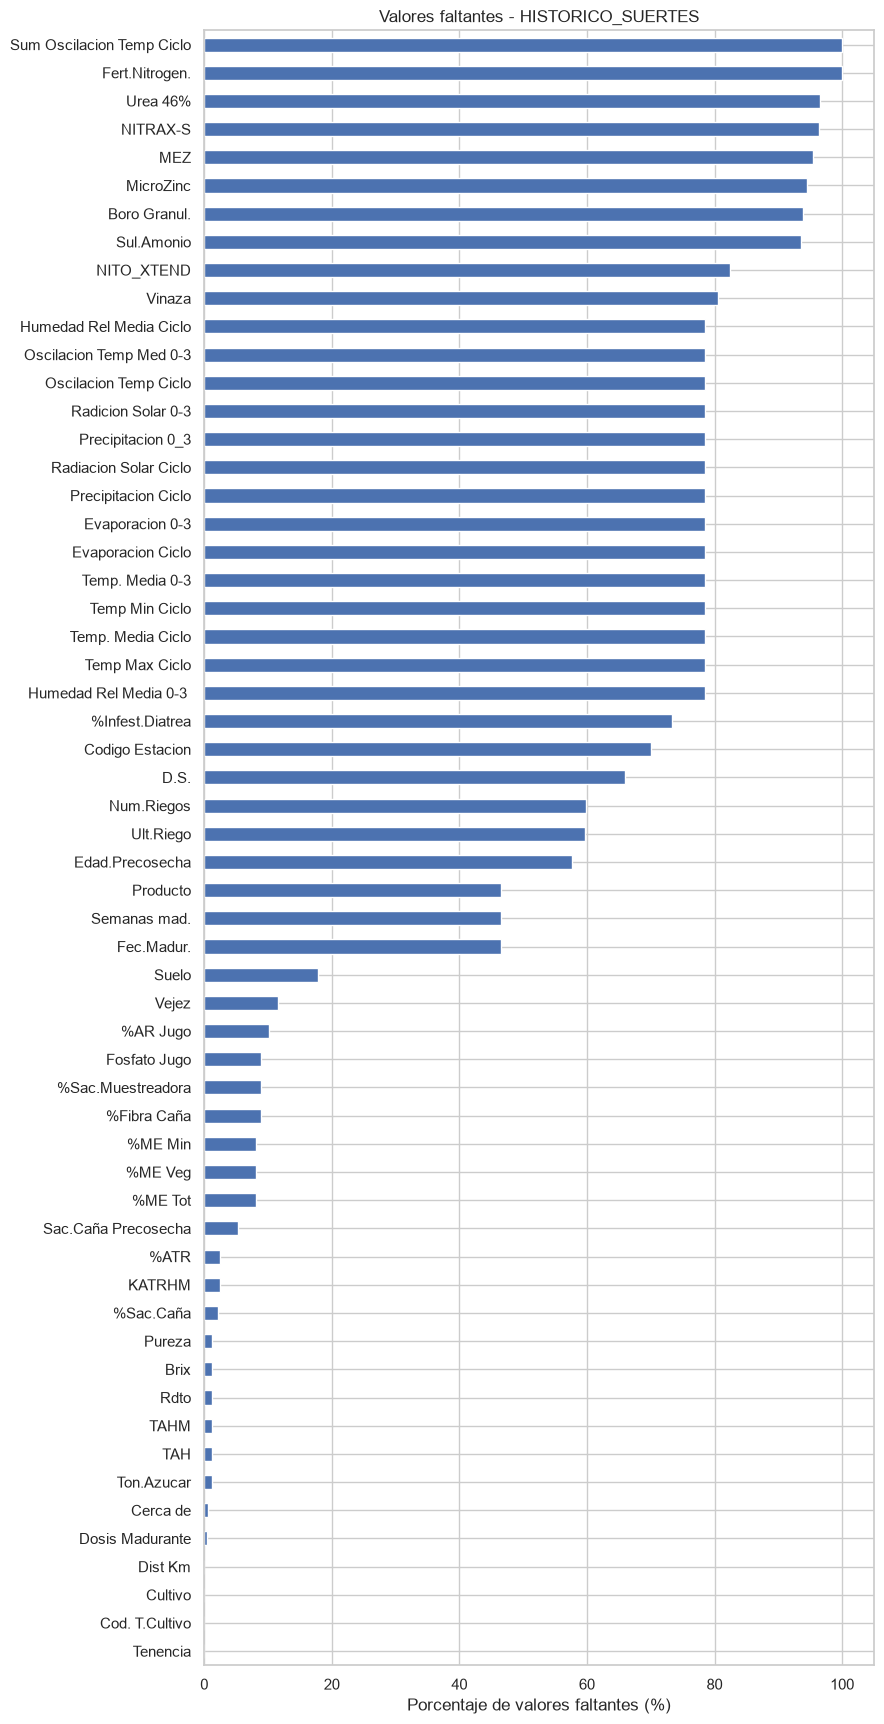

BD_IPSA_1940: no hay valores nulos.


In [7]:
def graficar_faltantes(df, nombre):
    porcentajes = df.isna().mean().mul(100)
    porcentajes = porcentajes[porcentajes > 0].sort_values()

    if porcentajes.empty:
        print(f"{nombre}: no hay valores nulos.")
        return

    porcentajes.plot(
        kind="barh",
        figsize=(9, max(4, len(porcentajes) * 0.3))
    )
    plt.xlabel("Porcentaje de valores faltantes (%)")
    plt.title(f"Valores faltantes - {nombre}")
    plt.tight_layout()
    plt.show()

graficar_faltantes(historico, "HISTORICO_SUERTES")
graficar_faltantes(ipsa, "BD_IPSA_1940")

#### 2.4.2 Duplicados y tipos de dato

In [8]:
def revisar_calidad(df, nombre):
    resumen = pd.DataFrame({
        "Tipo": df.dtypes.astype(str),
        "Faltantes": df.isna().sum(),
        "% faltantes": df.isna().mean() * 100,
        "Valores únicos": df.nunique()
    })

    resumen["% faltantes"] = resumen["% faltantes"].round(2)

    print(f"\nCalidad de datos: {nombre}")
    print("Filas duplicadas:", df.duplicated().sum())
    display(resumen.sort_values("% faltantes", ascending=False))

revisar_calidad(historico, "HISTORICO_SUERTES")
revisar_calidad(ipsa, "BD_IPSA_1940")


Calidad de datos: HISTORICO_SUERTES
Filas duplicadas: 0


,Tipo,Faltantes,% faltantes,Valores únicos
Sum Oscilacion Temp Ciclo,float64,21027,100.00,0
Fert.Nitrogen.,float64,21027,100.00,0
Urea 46%,float64,20304,96.56,413
NITRAX-S,float64,20279,96.44,430
MEZ,float64,20056,95.38,73
MicroZinc,float64,19878,94.54,70
Boro Granul.,float64,19742,93.89,76
Sul.Amonio,float64,19670,93.55,246
NITO_XTEND,float64,17348,82.50,313
Vinaza,float64,16929,80.51,2706



Calidad de datos: BD_IPSA_1940
Filas duplicadas: 0


,Tipo,Faltantes,% faltantes,Valores únicos
Unnamed: 0,int64,0,0.0,2187
NOME,object,0,0.0,285
FAZ,int64,0,0.0,285
TAL,object,0,0.0,273
tipocorte,object,0,0.0,1
variedad,object,0,0.0,1
madurada,object,0,0.0,1
producto,object,0,0.0,1
dosismad,float64,0,0.0,18
semsmad,float64,0,0.0,150


#### 2.4.3 Columnas vacías, constantes e identificadores

In [9]:
def variables_constantes(df):
    return [col for col in df.columns
        if df[col].nunique(dropna=True) <= 1]


print("Constantes en el histórico:")
print(variables_constantes(historico))

print("\nConstantes en IPSA:")
print(variables_constantes(ipsa))

Constantes en el histórico:
['Fert.Nitrogen.', 'Sum Oscilacion Temp Ciclo']

Constantes en IPSA:
['tipocorte', 'variedad', 'madurada', 'producto']


In [10]:
print("Columnas completamente vacías:")
print(historico.columns[historico.isna().all()].tolist())

print("\nPosibles identificadores en IPSA:")
display(ipsa[["Unnamed: 0", "NOME", "FAZ", "TAL"]].head())

Columnas completamente vacías:
['Fert.Nitrogen.', 'Sum Oscilacion Temp Ciclo']

Posibles identificadores en IPSA:


,Unnamed: 0,NOME,FAZ,TAL
0,11,AMAIME SILCA,81291,40
1,12,AMAIME SILCA,81291,41
2,13,AMAIME SILCA,81291,41
3,15,AMAIME SILCA,81291,43
4,16,AMAIME SILCA,81291,43


Según los resultados, las columnas completamente vacías del histórico son Fert.Nitrogen. y Sum Oscilacion Temp Ciclo. En IPSA, tipocorte, variedad, madurada y producto son constantes. Las primeras dos pueden excluirse del análisis actual; las constantes de IPSA no aportan información predictiva en este archivo.

El histórico presenta una cantidad importante de valores faltantes en algunas variables de fertilización y clima. Las columnas completamente vacías no aportan información y se excluirán de la copia de trabajo. Las demás variables con muchos faltantes se evaluarán individualmente antes de decidir si se eliminan o se conservan.

En el dataset IPSA no se detectaron valores faltantes en el resumen inicial. Sin embargo, se identificaron variables constantes que no aportan capacidad para distinguir las observaciones. También se revisarán las columnas que parecen identificadores antes de decidir su tratamiento.

### 2.5 Copias de trabajo para el EDA

Con el fin de no trabajar con los datasets originales, se hacen unas copias para la realización del EDA.
En estos nuevos datasets se toman las decisiones importantes sobre el diseño y la comprensión del proyecto; de esta manera se excluyen los datos o columnas que se identificaron como no útiles.

In [11]:
historico_eda = historico.drop(
    columns=["Fert.Nitrogen.","Sum Oscilacion Temp Ciclo"],errors="ignore").copy()
#Preguntar profe: Unnamed: 0 se excluye inicialmente porque parece un índice importado?
ipsa_eda = ipsa.drop(
    columns=["Unnamed: 0", "tipocorte","variedad","madurada","producto"],errors="ignore").copy()

print("Dimensiones del histórico:", historico_eda.shape)
print("Dimensiones de IPSA:", ipsa_eda.shape)

Dimensiones del histórico: (21027, 83)
Dimensiones de IPSA: (2187, 16)


In [12]:
# Revisar columnas constantes de IPSA
columnas_constantes = [
    col for col in ipsa_eda.columns
    if ipsa_eda[col].nunique(dropna=False) <= 1
]

print("Columnas constantes en IPSA:", columnas_constantes)

# Eliminar columnas constantes porque no ayudan a distinguir registros
ipsa_eda = ipsa_eda.drop(columns=columnas_constantes)

print("Dimensiones del histórico:", historico_eda.shape)
print("Dimensiones de IPSA:", ipsa_eda.shape)

Columnas constantes en IPSA: []
Dimensiones del histórico: (21027, 83)
Dimensiones de IPSA: (2187, 16)


Las columnas constantes se eliminan porque no permiten diferenciar unas observaciones de otras. Esto no implica eliminar las columnas que identifican haciendas o suertes sin antes determinar si son necesarias para agrupar los datos o separar entrenamiento y prueba.

### 2.6 Análisis univariado

Se estudiará la distribución individual de las variables numéricas mediante estadísticas descriptivas, histogramas y diagramas de caja. Esto permite identificar asimetrías, concentraciones de valores, posibles errores y observaciones extremas.

Los valores atípicos no se eliminarán automáticamente: primero se verificará si son errores de registro o valores posibles dentro del proceso agrícola.

In [13]:
print("Estadísticas de las variables numéricas del histórico:")
display(historico_eda.describe().T)

print("Estadísticas de las variables numéricas de IPSA:")
display(ipsa_eda.describe().T)

Estadísticas de las variables numéricas del histórico:


,count,mean,min,25%,50%,75%,max,std
Período,21027.0,202039.708708,201701.0,201812.0,202010.0,202209.0,202407.0,216.642895
Hacienda,21027.0,80679.334427,80100.0,80247.0,80453.0,81104.0,82557.0,590.03015
Tenencia,21026.0,46.44873,11.0,31.0,51.0,51.0,91.0,21.513498
Area Neta,21027.0,8.642948,0.004,3.31,7.0,12.075,65.0,7.049533
Dist Km,21022.0,25.311806,1.1,12.0,21.9,32.7,155.0,18.237344
Cod.Estado #,21027.0,4.261806,0.0,1.0,3.0,6.0,31.0,4.111935
F.Siembra,21027,2015-03-11 18:18:44.839492096,1986-04-30 00:00:00,2013-03-13 00:00:00,2015-11-10 00:00:00,2018-08-07 00:00:00,2023-09-08 00:00:00,NaN
Ult.Riego,8470,2020-02-16 21:24:26.351829760,2016-01-12 00:00:00,2018-03-07 00:00:00,2019-08-14 00:00:00,2022-05-19 00:00:00,2024-06-27 00:00:00,NaN
Edad Ult Cos,21027.0,13.01111,1.31,11.93,12.62,13.86,78.19,1.97907
F.Ult.Corte,21027,2020-10-27 09:01:09.339420672,2017-01-02 00:00:00,2018-12-14 00:00:00,2020-10-11 00:00:00,2022-09-25 00:00:00,2024-07-10 00:00:00,NaN


Estadísticas de las variables numéricas de IPSA:


,count,mean,std,min,25%,50%,75%,max
FAZ,2187.0,80588.332876,572.818299,80100.0,80222.0,80396.0,80660.0,82519.0
dosismad,2187.0,0.993278,0.309096,0.0,0.8,1.0,1.2,9.0
semsmad,2187.0,9.164838,3.441579,-1.6,7.1,8.7,10.6,45.0
edad,2187.0,12.766118,1.117866,10.3,12.0,12.5,13.3,21.1
cortes,2187.0,2.794239,1.621195,1.0,1.0,2.0,4.0,14.0
me,2187.0,9.197759,1.574409,3.4,8.2,9.1,10.1,15.0
vejez,2187.0,4.172154,6.339255,0.2,2.1,2.6,3.3,102.9
sacarosa,2187.0,12.777732,0.854397,9.2,12.2,12.8,13.3,16.0
mes,2187.0,6.758573,3.482444,1.0,4.0,7.0,10.0,12.0
periodo,2187.0,201887.691358,131.982686,201407.0,201807.0,201908.0,202005.0,202101.0


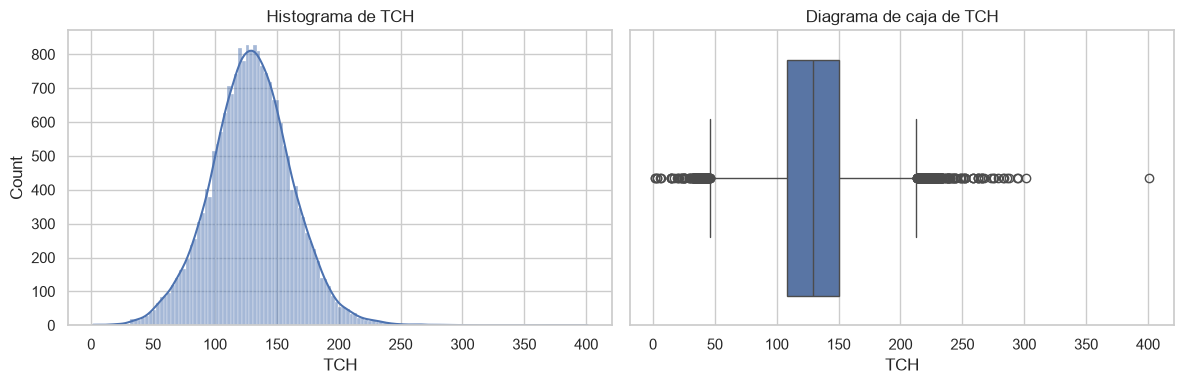

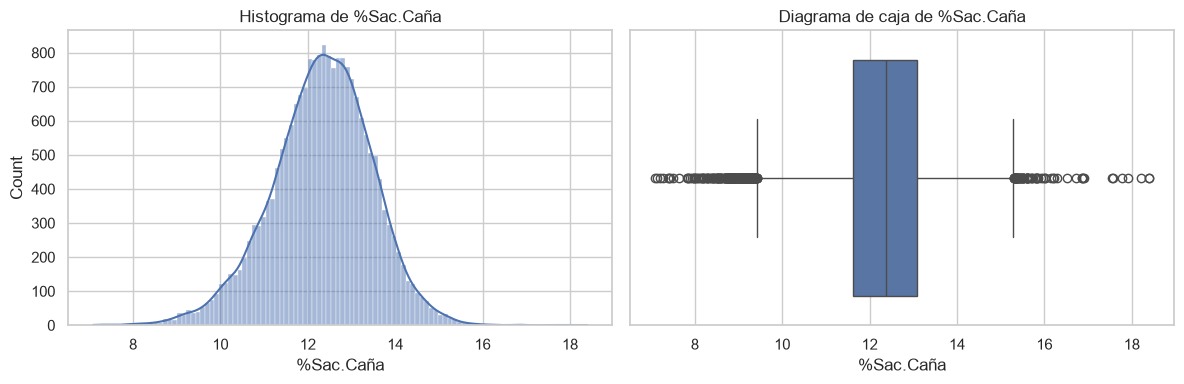

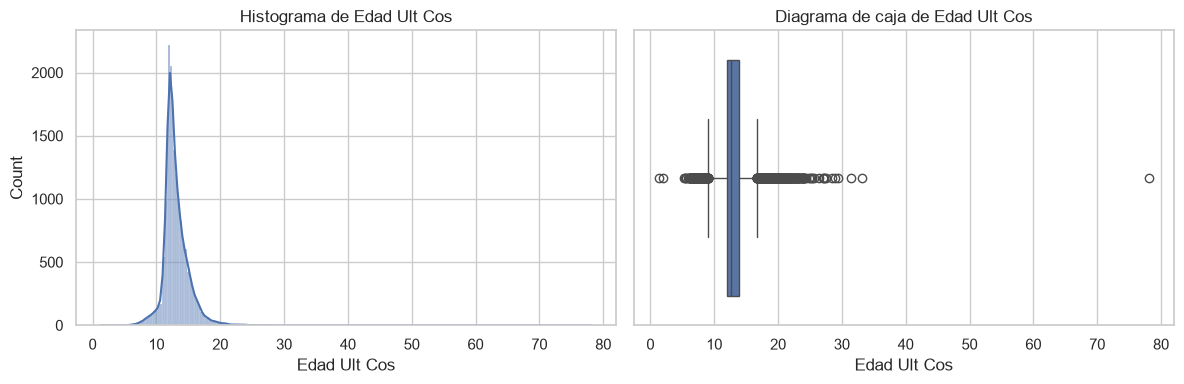

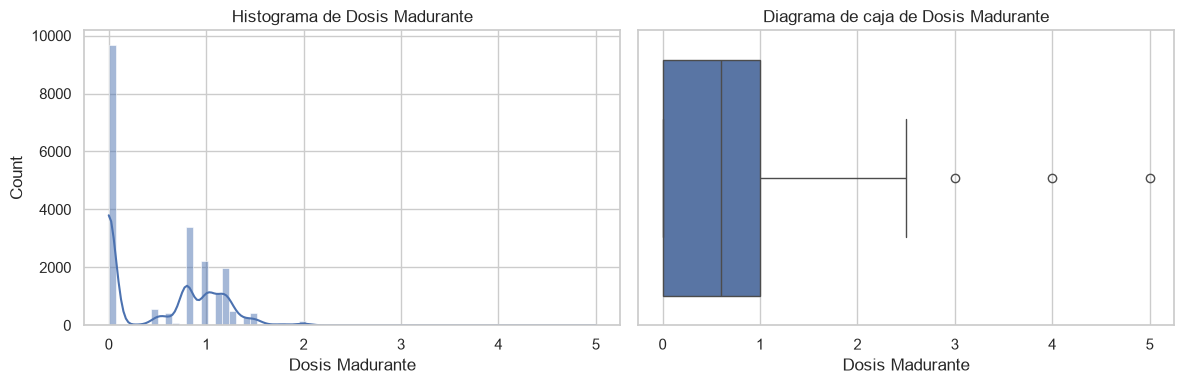

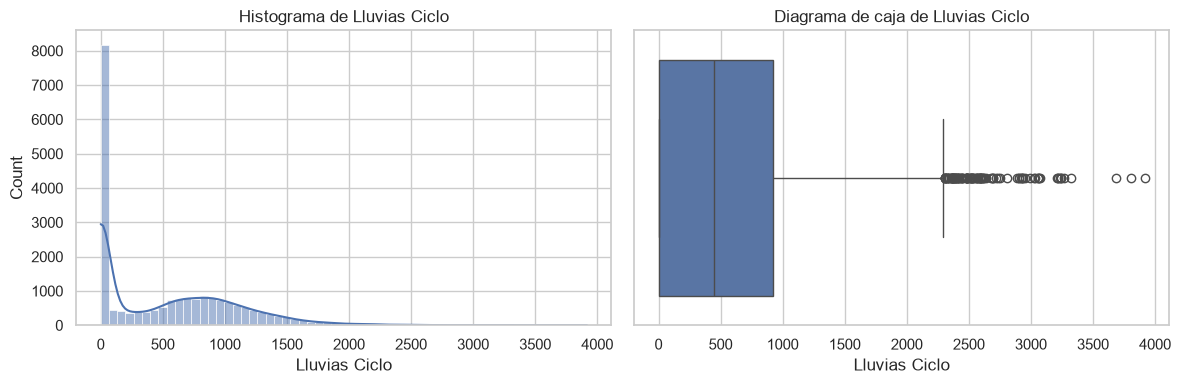

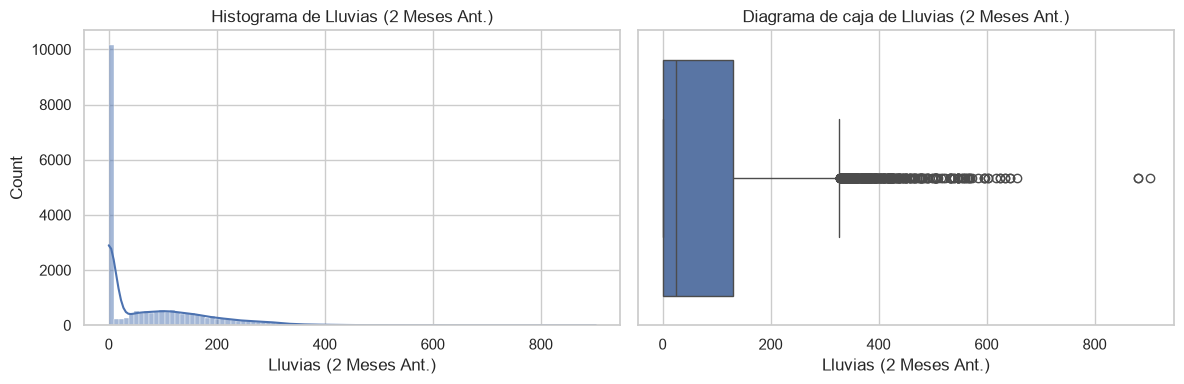

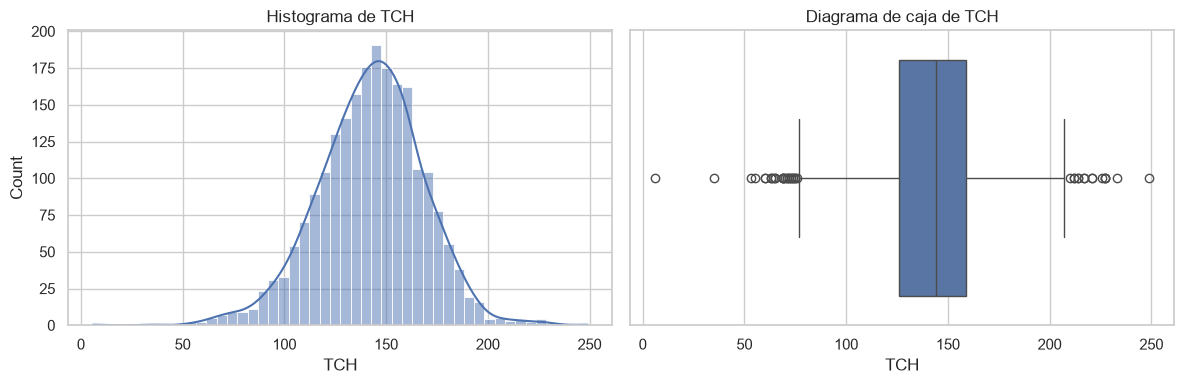

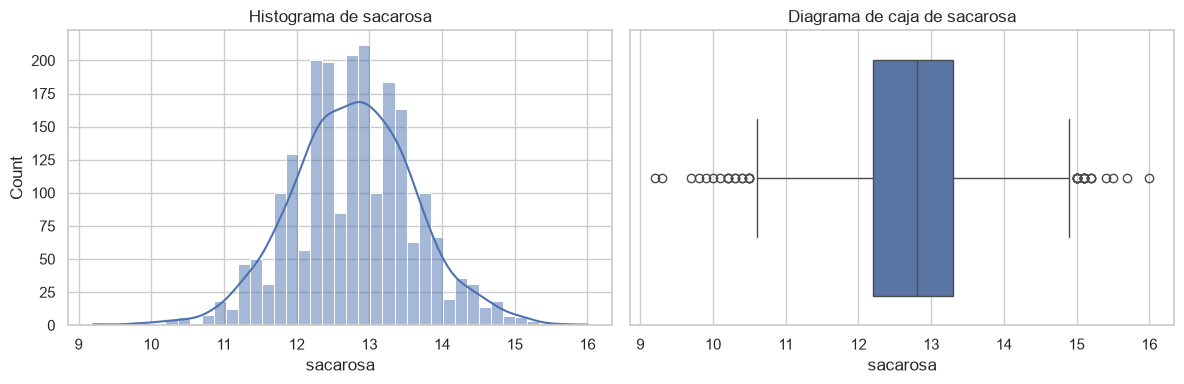

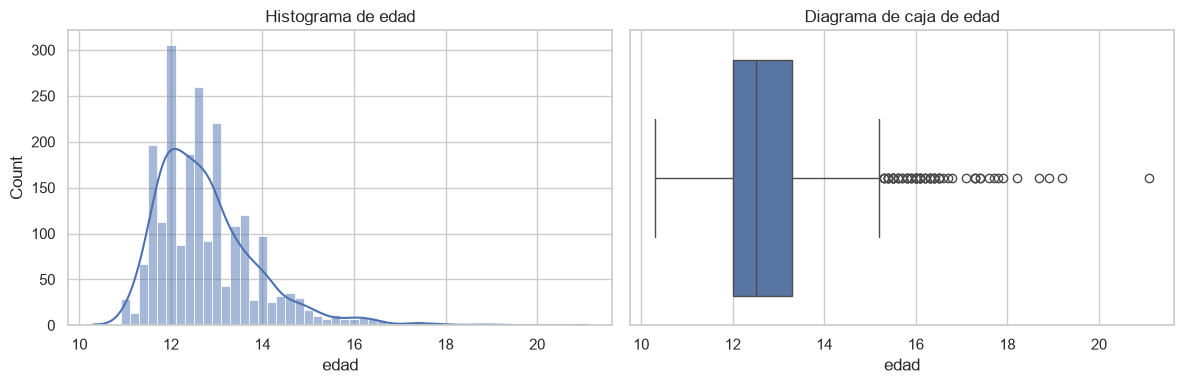

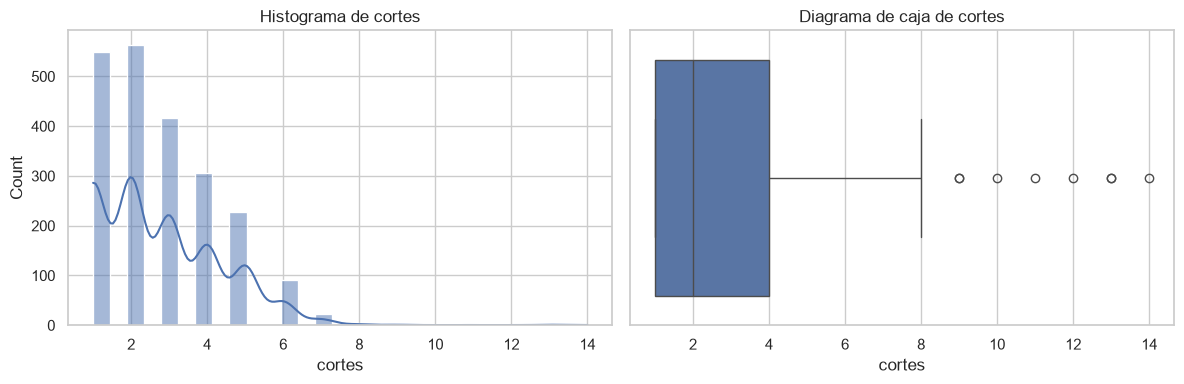

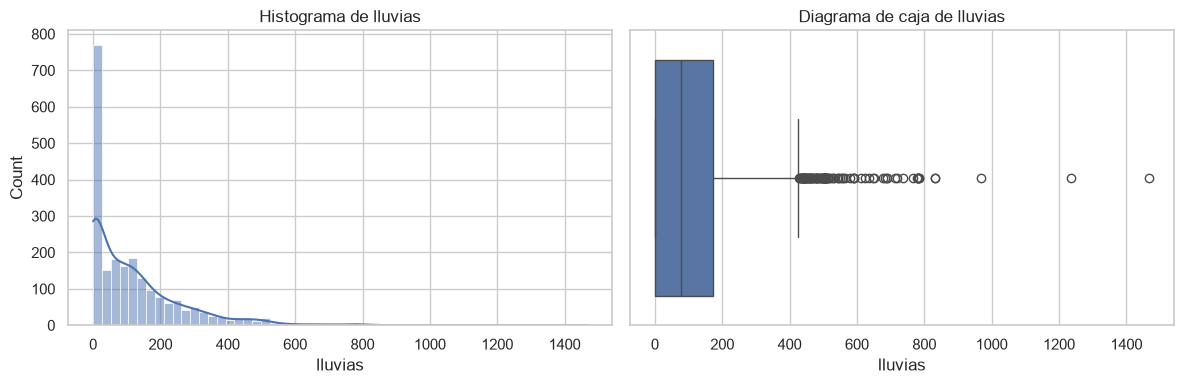

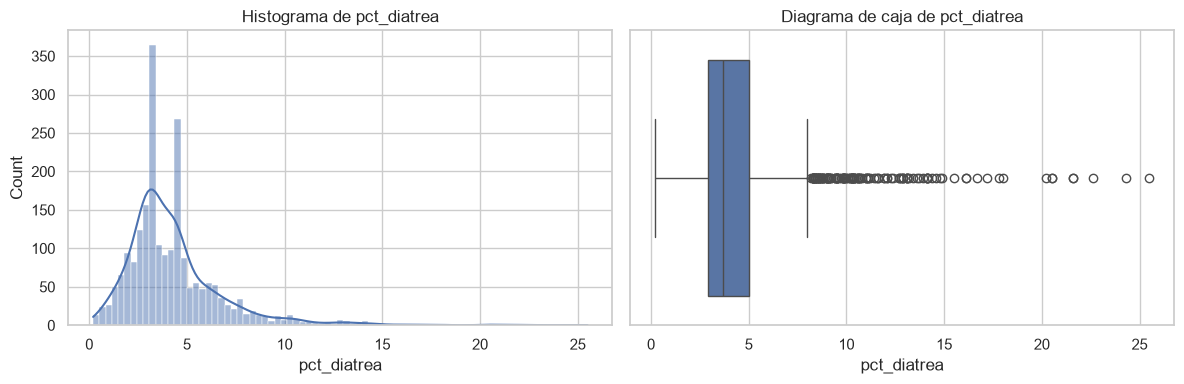

In [14]:
variables_historico = [
    "TCH",
    "%Sac.Caña",
    "Edad Ult Cos",
    "Dosis Madurante",
    "Lluvias Ciclo",
    "Lluvias (2 Meses Ant.)"
]

variables_ipsa = [
    "TCH",
    "sacarosa",
    "edad",
    "cortes",
    "lluvias",
    "pct_diatrea"
]


def analizar_distribuciones(df, columnas, nombre):
    for col in columnas:
        if col not in df.columns:
            print(f"No existe la columna: {col}")
            continue

        valores = pd.to_numeric(df[col], errors="coerce").dropna()

        if valores.empty:
            continue

        fig, axes = plt.subplots(1, 2, figsize=(12, 4))

        sns.histplot(valores, kde=True, ax=axes[0])
        axes[0].set_title(f"Histograma de {col}")

        sns.boxplot(x=valores, ax=axes[1])
        axes[1].set_title(f"Diagrama de caja de {col}")

        plt.tight_layout()
        plt.show()


analizar_distribuciones(
    historico_eda, variables_historico, "Histórico"
)

analizar_distribuciones(
    ipsa_eda, variables_ipsa, "IPSA"
)

### 2.7 Detección de valores inconsistentes

En las gráficas anteriores se observaron valores atípicos que es necesario revisar: valores negativos, ceros y registros que podrían estar fuera de los rangos esperados.

Estos valores no se eliminarán automáticamente: primero se identificarán para determinar si representan errores o situaciones reales.

In [15]:
# Variables que requieren una revisión inicial
variables_revision = [
    "Area Neta",
    "Edad Ult Cos",
    "Semanas mad.",
    "TCH",
    "%Sac.Caña",
    "Brix",
    "Pureza",
    "Dosis Madurante"
]

for col in variables_revision:
    if col in historico.columns:
        valores = pd.to_numeric(historico[col], errors="coerce")

        print(f"\n--- {col} ---")
        print("Valores negativos:", (valores < 0).sum())
        print("Valores iguales a cero:", (valores == 0).sum())
        print("Valores faltantes:", valores.isna().sum())


--- Area Neta ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 0

--- Edad Ult Cos ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 0

--- Semanas mad. ---
Valores negativos: 13
Valores iguales a cero: 2
Valores faltantes: 9775

--- TCH ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 0

--- %Sac.Caña ---
Valores negativos: 0
Valores iguales a cero: 0
Valores faltantes: 449

--- Brix ---
Valores negativos: 0
Valores iguales a cero: 1857
Valores faltantes: 267

--- Pureza ---
Valores negativos: 0
Valores iguales a cero: 1854
Valores faltantes: 269

--- Dosis Madurante ---
Valores negativos: 0
Valores iguales a cero: 9685
Valores faltantes: 104


In [16]:
historico.loc[
    pd.to_numeric(historico["Semanas mad."], errors="coerce") < 0,
    ["Período", "Hacienda", "Suerte", "Semanas mad."]
].head(20)

,Período,Hacienda,Suerte,Semanas mad.
3734,201805,80114,600,-1.285714
3748,201806,80114,517B,-1.142857
5223,201812,81386,001,-1.571428
7535,201910,80508,002A,-2.000000
8319,202001,80274,005,-0.428571
9799,202007,81143,002,-0.428571
11050,202012,81052,002,-0.428571
11578,202103,80108,325,-2.000000
12237,202107,82502,002,-0.714285
14808,202206,80176,001,-0.714285


### 2.8 Correlaciones iniciales con las variables objetivo

In [17]:
def correlaciones_objetivo(df, objetivo):
    datos = df.select_dtypes(include="number")

    if objetivo not in datos.columns:
        print(f"No se encontró {objetivo} como variable numérica.")
        return

    correlaciones = (
        datos.corr(method="spearman", min_periods=100)[objetivo]
        .drop(objetivo)
        .dropna()
        .sort_values(key=abs, ascending=False)
    )

    return correlaciones.to_frame("Correlación de Spearman")


correlaciones_objetivo(historico_eda, "TCH").head(15)

,Correlación de Spearman
TAH,0.895056
TCHM,0.834753
KATRHM,0.791229
TAHM,0.762748
TonUltCorte,0.340939
Ton.Azucar,0.318425
Edad Ult Cos,0.303779
Cod.Estado #,-0.291462
Evaporacion Ciclo,0.274624
%ATR,-0.192435


In [18]:
correlaciones_objetivo(ipsa_eda, "sacarosa").head(15)

,Correlación de Spearman
me,-0.285044
TCH,-0.203176
semsmad,0.177902
periodo,0.140923
mes,0.137679
pct_diatrea,-0.085545
lluvias,-0.074567
grupo_tenencia,-0.060266
vejez,-0.049188
FAZ,-0.041051


In [19]:
correlaciones_objetivo(ipsa_eda, "TCH").head(15)

,Correlación de Spearman
cortes,-0.266893
periodo,-0.235450
sacarosa,-0.203176
edad,0.153529
grupo_tenencia,0.144829
vejez,-0.102092
FAZ,0.100957
pct_diatrea,0.098559
dosismad,0.060819
me,0.016775


**Dataset IPSA.** Las correlaciones de Spearman permitieron identificar las variables con mayor asociación monotónica con las variables objetivo.

Para la sacarosa, la variable `me` presentó la asociación más alta (ρ = -0.285), seguida por `TCH` (ρ = -0.203) y `semsmad` (ρ = 0.178). Estos resultados indican que `me` y `TCH` tienden a asociarse con menores niveles de sacarosa, mientras que un mayor número de semanas de maduración se relaciona con un ligero incremento del contenido de azúcar.

En el caso de TCH, la variable `cortes` mostró la asociación más importante (ρ = -0.267), lo que sugiere que un mayor número de cortes tiende a asociarse con menores rendimientos. También se observaron asociaciones moderadas con `periodo` (ρ = -0.235) y `sacarosa` (ρ = -0.203), así como asociaciones positivas más débiles con `edad` y `grupo_tenencia`.

Aunque la mayoría de las correlaciones son bajas o moderadas, estos resultados constituyen una guía inicial para seleccionar variables candidatas. La decisión final también tendrá en cuenta el contexto agronómico, la calidad de los datos y la necesidad de evitar variables que puedan introducir fuga de información en los modelos.

### 2.9 Selección y justificación de variables

In [20]:
# Cod.Estado # resultó ser el número de corte (0 = plantilla); el TCH baja con cada corte
display(historico_eda.groupby(["Cod.Estado #", "Cod.Estado"])["TCH"].mean().round(1).head(8))

Cod.Estado #  Cod.Estado
0             Plantilla     148.3
1             Corte 1       139.2
2             Corte 2       132.8
3             Corte 3       127.9
4             Corte 4       124.1
5             Corte 5       123.7
6             Corte 6       120.7
7             Corte 7       120.0
Name: TCH, dtype: float64

In [21]:
# Variables calculadas con el propio objetivo o medidas en la cosecha (fuga de información)
fuga = ["TonUltCorte", "TCHM", "TAH", "TAHM", "Ton.Azucar", "KATRHM", "Rdto", "%ATR",
        "Brix", "Pureza", "%Sac.Muestreadora", "Sac.Caña Precosecha", "%Fibra Caña",
        "%AR Jugo", "%ME Min", "%ME Veg", "%ME Tot", "Fosfato Jugo"]

# Variables con más del 50 % de faltantes (clima, fertilizantes, diatrea, riegos)
alto_faltante = faltantes_historico.index[faltantes_historico["Porcentaje nulo"] > 50].tolist()

predictores_tch = ["Edad Ult Cos", "Cod.Estado #", "Variedad", "Suelo", "Zona", "Tenencia",
                   "Area Neta", "Dist Km", "Cultivo", "Tipo Quema", "T.Corte",
                   "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve", "Luvias 9 -FC",
                   "M3 Riego", "Edad Plantacion (años)", "Mes Corte"]

predictores_sacarosa = ["Edad Ult Cos", "Cod.Estado #", "Variedad", "Suelo", "Zona", "Tenencia",
                        "Cultivo", "Tipo Quema", "T.Corte", "Dosis Madurante", "Semanas mad.",
                        "Lluvias (2 Meses Ant.)", "Lluvias Ciclo", "M3 Riego",
                        "Edad Plantacion (años)", "Mes Corte"]

**Justificación:**
- **Se usan** las variables que la Tarea 1 señala como determinantes:
  - Edad de cosecha y número de corte.
  - Variedad y suelo.
  - Lluvias y riego.
  - Variables de maduración, para la sacarosa.
  - Ubicación y forma de cosecha.
- **Se descartan por fuga de información** TonUltCorte, TCHM, TAH, %ATR, Brix, Pureza y similares. Se calculan con el propio objetivo (por ejemplo, TCH = TonUltCorte / Area Neta) o se miden en el mismo análisis de laboratorio que la sacarosa, así que no se conocen antes de cosechar.
- **Se descartan por ser identificadores o fechas crudas:** Nombre, Hacienda, Suerte, Período, Cosechó y Codigo Estacion. Las fechas se convierten en edades y meses en 2.12.
- **Se descartan por tener más del 50 % de faltantes:** clima de estaciones (78 %), fertilizantes (80–97 %), diatrea (73 %) y número de riegos (60 %).
- **También se descartan:**
  - `Vejez`, porque su significado no es claro en el diccionario de datos.
  - `Producto`, porque el 92 % de las suertes maduradas usa el mismo producto.
  - El otro objetivo, porque TCH y %Sac.Caña se miden al mismo tiempo.

### 2.10 Tratamiento de inconsistencias y valores atípicos

In [22]:
# 1. La caña para semilla no es una cosecha comercial
display(historico_eda.groupby("Destino 1=Semilla")[["TCH", "Edad Ult Cos"]].mean().round(1))

# 2. Un ciclo de ~12 meses con 0 mm de lluvia no es posible en el Valle del Cauca
sin_lluvia = historico_eda["Lluvias Ciclo"] == 0
print("Suertes con Lluvias Ciclo = 0:", round(sin_lluvia.mean() * 100, 1), "%")
print("% sin lluvia por año:", sin_lluvia.groupby(historico_eda["Período"] // 100).mean().round(2).to_dict())

,TCH,Edad Ult Cos
Destino 1=Semilla,,
0,130.1,13.1
1,96.6,9.2


Suertes con Lluvias Ciclo = 0: 36.8 %
% sin lluvia por año: {2017: 0.32, 2018: 0.32, 2019: 0.42, 2020: 0.39, 2021: 0.27, 2022: 0.28, 2023: 0.49, 2024: 0.52}


- **Caña para semilla:** rinde 33 t/ha menos y se cosecha a los 9 meses. Se elimina porque no representa una cosecha comercial.
- **Lluvias:** el 37 % de las suertes tiene **0 mm en todo el ciclo**, y ese porcentaje cambia mucho de un año a otro (hasta 52 % en 2024). No es un año seco, es **falta de registro**. Por eso esos ceros se convierten en `NaN` en vez de dejarlos como si no hubiera llovido.
- **Valores imposibles:** semanas de maduración negativas o mayores a 30, edades de cosecha fuera de 6–24 meses y TCH menor a 30 t/ha (menos de un cuarto de la mediana).

Registros: 21027 -> 20676 (1.7% eliminados)


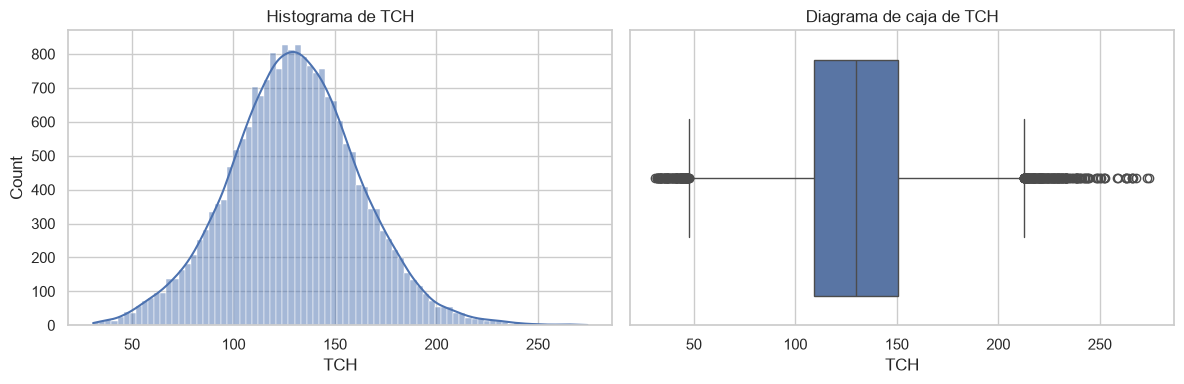

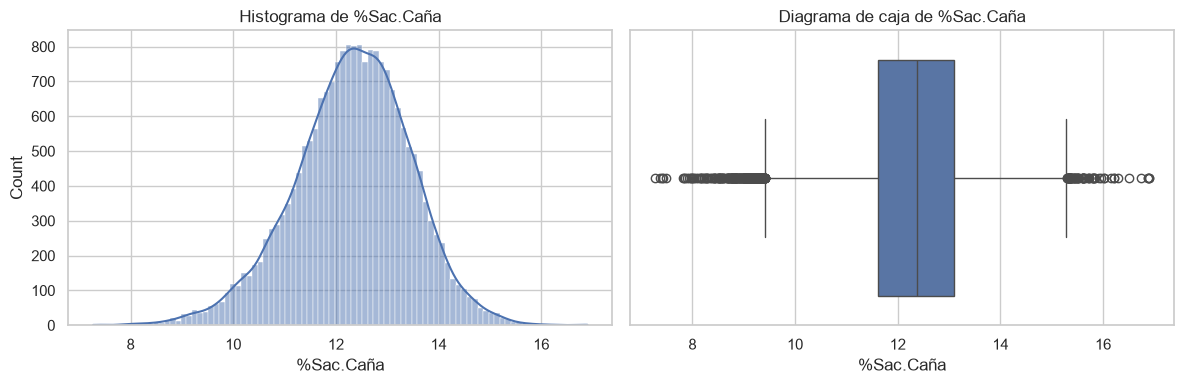

In [23]:
LLUVIAS = ["Lluvias Ciclo", "Lluvias 0 -3", "Lluvias tres a seis", "Lluvias seis a nueve",
           "Luvias 9 -FC", "Lluvias (2 Meses Ant.)"]


def limites_iqr(serie, factor=3):
    # Regla de Tukey con factor 3: solo marca los valores muy extremos
    q1, q3 = serie.quantile([0.25, 0.75])
    return q1 - factor * (q3 - q1), q3 + factor * (q3 - q1)


def limpiar_historico(df):
    df = df.copy()
    n_inicial = len(df)

    # Textos inconsistentes (ej. "ip05" vs "IP05", espacios al final)
    for col in ["Zona", "Suelo", "Variedad"]:
        df[col] = df[col].str.upper().str.strip()

    # Valores imposibles -> faltante
    df.loc[(df["Semanas mad."] < 0) | (df["Semanas mad."] > 30), "Semanas mad."] = np.nan
    df.loc[df["Lluvias Ciclo"] == 0, LLUVIAS] = np.nan

    # Registros que no representan una cosecha comercial normal
    df = df[df["Destino 1=Semilla"] == 0]
    df = df[df["Edad Ult Cos"].between(6, 24)]
    df = df[df["TCH"].between(30, limites_iqr(df["TCH"])[1])]
    inferior, superior = limites_iqr(df["%Sac.Caña"].dropna())
    df = df[df["%Sac.Caña"].isna() | df["%Sac.Caña"].between(inferior, superior)]

    print(f"Registros: {n_inicial} -> {len(df)} ({(n_inicial - len(df)) / n_inicial:.1%} eliminados)")
    return df


historico_limpio = limpiar_historico(historico_eda)
analizar_distribuciones(historico_limpio, ["TCH", "%Sac.Caña"], "Histórico limpio")

### 2.11 Tratamiento de datos faltantes

In [24]:
# Si no hay producto madurante, tampoco hay semanas de maduración: la suerte no se maduró
display(pd.crosstab(historico_limpio["Producto"].isna(), historico_limpio["Semanas mad."].isna(),
                    rownames=["Producto faltante"], colnames=["Semanas faltante"]))

Semanas faltante,False,True
Producto faltante,,
False,11090,123
True,3,9460


In [25]:
def imputar_historico(df):
    df = df.copy()

    # Sin madurante -> dosis y semanas = 0
    sin_madurante = df["Producto"].isna()
    df.loc[sin_madurante, ["Dosis Madurante", "Semanas mad."]] = 0

    # Suelo desconocido como categoría propia (imputar la moda inventaría el 18 % de los suelos)
    df["Suelo"] = df["Suelo"].fillna("DESCONOCIDO")

    # La distancia al ingenio es la misma para toda la hacienda
    df["Dist Km"] = df["Dist Km"].fillna(df.groupby("Hacienda")["Dist Km"].transform("median"))

    return df.drop(columns=alto_faltante + fuga, errors="ignore")


historico_limpio = imputar_historico(historico_limpio)

faltan = historico_limpio.isna().mean().mul(100).round(1)
print(faltan[faltan > 0].sort_values(ascending=False))

Fec.Madur.                45.8
Producto                  45.8
Lluvias (2 Meses Ant.)    37.3
Lluvias Ciclo             37.3
Lluvias seis a nueve      37.3
Luvias 9 -FC              37.3
Lluvias tres a seis       37.3
Lluvias 0 -3              37.3
Vejez                     10.8
%Sac.Caña                  0.7
Semanas mad.               0.6
Cerca de                   0.6
dtype: float64


| Variable | Estrategia | Por qué |
|---|---|---|
| Dosis y semanas de maduración (46 % nulos) | 0 | Los faltantes coinciden con la falta de producto: no se aplicó madurante |
| Suelo (18 %) | "DESCONOCIDO" | Es más honesto que inventar un suelo |
| Dist Km (0,02 %) | Mediana de su hacienda | La distancia depende de la hacienda |
| Lluvias (37 %) | Se quedan como `NaN` | Se imputan en la Tarea 3 **dentro del Pipeline**, con la mediana del conjunto de entrenamiento (`SimpleImputer(add_indicator=True)`) |
| %Sac.Caña (objetivo) | Se eliminan esas filas solo en el modelo de sacarosa | Un objetivo nunca se imputa |

Las demás columnas con nulos (fechas crudas, identificadores) no entran a los modelos.

### 2.12 Variables derivadas

In [26]:
# Años desde la siembra hasta el corte y mes de cosecha (estacionalidad)
historico_limpio["Edad Plantacion (años)"] = (
    (historico_limpio["F.Ult.Corte"] - historico_limpio["F.Siembra"]).dt.days / 365.25)
historico_limpio["Mes Corte"] = historico_limpio["F.Ult.Corte"].dt.month

# Tenencia es un código, no una cantidad
historico_limpio["Tenencia"] = historico_limpio["Tenencia"].astype("Int64").astype(str)

# Categorías con menos de 100 registros -> "OTRAS" (evita cientos de columnas dummy)
for col in ["Variedad", "Suelo", "Zona", "Tenencia"]:
    conteo = historico_limpio[col].value_counts()
    historico_limpio[col] = historico_limpio[col].where(
        ~historico_limpio[col].isin(conteo[conteo < 100].index), "OTRAS")
    print(f"{col}: {conteo.size} -> {historico_limpio[col].nunique()} categorías")

Variedad: 57 -> 19 categorías
Suelo: 103 -> 33 categorías
Zona: 6 -> 6 categorías
Tenencia: 8 -> 7 categorías


### 2.13 Distribución y normalidad de TCH y %Sac.Caña

In [27]:
#Hay qye identificar los nombres exactos de las columnas objetivo:

TCH: asimetría = 0.11, p-valor D'Agostino = 1.1e-25
%Sac.Caña: asimetría = -0.28, p-valor D'Agostino = 6.5e-80


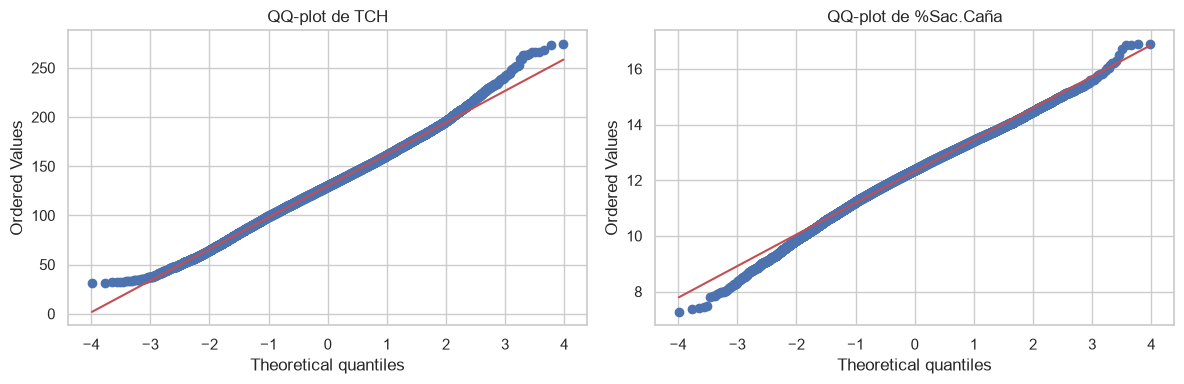

In [28]:
for col in ["TCH", "%Sac.Caña"]:
    serie = historico_limpio[col].dropna()
    print(f"{col}: asimetría = {serie.skew():.2f}, p-valor D'Agostino = {stats.normaltest(serie).pvalue:.1e}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
stats.probplot(historico_limpio["TCH"], plot=axes[0])
axes[0].set_title("QQ-plot de TCH")
stats.probplot(historico_limpio["%Sac.Caña"].dropna(), plot=axes[1])
axes[1].set_title("QQ-plot de %Sac.Caña")
plt.tight_layout()
plt.show()

Las dos variables son casi simétricas (|asimetría| < 0,3) y el QQ-plot sigue la línea salvo en las colas. La prueba rechaza la normalidad solo porque con ~20 000 datos cualquier desviación mínima sale significativa. **No hace falta transformarlas.** Lo que sí debe ser normal en la regresión lineal son los residuos, y eso se revisa en la Tarea 3.

### 2.14 Relaciones entre predictores y objetivos

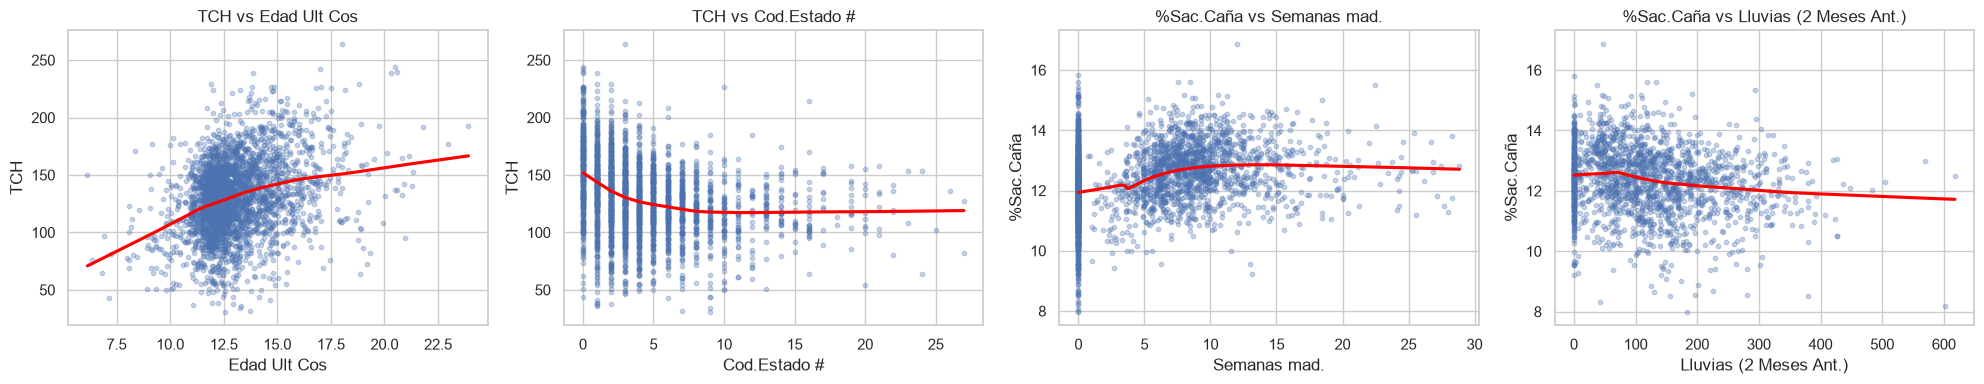

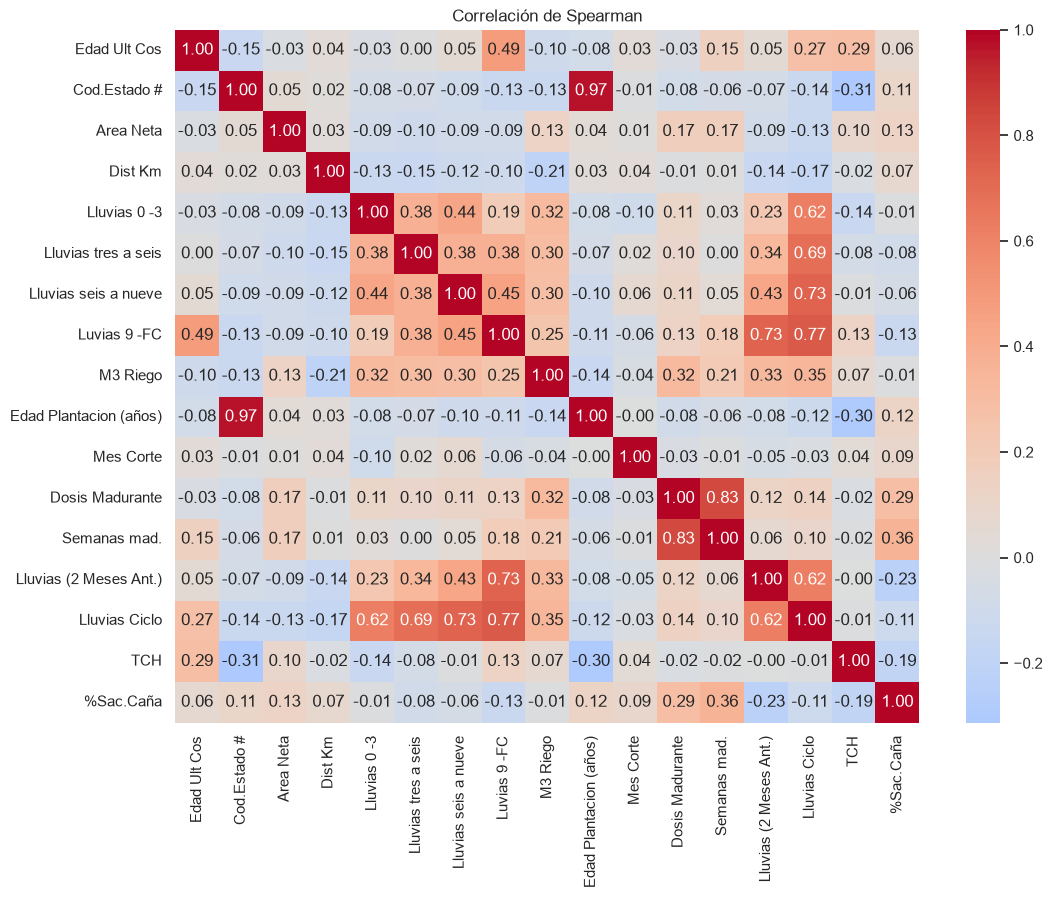

In [29]:
pares = [("Edad Ult Cos", "TCH"), ("Cod.Estado #", "TCH"),
         ("Semanas mad.", "%Sac.Caña"), ("Lluvias (2 Meses Ant.)", "%Sac.Caña")]
muestra = historico_limpio.sample(3000, random_state=42)

fig, axes = plt.subplots(1, 4, figsize=(20, 4))
for ax, (x, y) in zip(axes, pares):
    sns.regplot(data=muestra, x=x, y=y, ax=ax, lowess=True,
                scatter_kws={"alpha": 0.3, "s": 10}, line_kws={"color": "red"})
    ax.set_title(f"{y} vs {x}")
plt.tight_layout()
plt.show()

numericas_corr = historico_limpio[list(dict.fromkeys(
    predictores_tch + predictores_sacarosa + ["TCH", "%Sac.Caña"]))].select_dtypes("number").columns
plt.figure(figsize=(12, 9))
sns.heatmap(historico_limpio[numericas_corr].corr(method="spearman"), annot=True, fmt=".2f",
            cmap="coolwarm", center=0)
plt.title("Correlación de Spearman")
plt.show()

**Lo que muestran las gráficas:**
- **TCH:**
  - Sube con la edad de cosecha hasta unos 15 meses y luego se aplana.
  - Baja con cada corte, desde la plantilla hasta el corte 6, y después se estabiliza.
- **%Sac.Caña:**
  - Sube con las semanas de maduración hasta unas 10 semanas.
  - Baja cuando llueve en los 2 meses previos a la cosecha, porque la lluvia diluye el azúcar.

Varias de estas relaciones son curvas y no rectas, lo que justifica probar Random Forest o XGBoost en la Tarea 3.

En el heatmap, `Cod.Estado #` y `Edad Plantacion` están casi duplicadas (0,98), y las lluvias por etapa se parecen mucho a `Lluvias Ciclo`. Esto se confirma con el VIF.

### 2.15 Multicolinealidad (VIF)

In [30]:
def calcular_vif(df, columnas):
    datos = sm.add_constant(df[columnas].select_dtypes("number").dropna())
    vif = pd.Series([variance_inflation_factor(datos.values, i) for i in range(datos.shape[1])],
                    index=datos.columns).drop("const")
    return vif.sort_values(ascending=False).round(2)


print("VIF con todos los predictores de TCH:")
print(calcular_vif(historico_limpio, predictores_tch).head(4))

# Para la regresión lineal se quita Edad Plantacion (duplica a Cod.Estado #)
predictores_tch_lineal = [c for c in predictores_tch if c != "Edad Plantacion (años)"]
predictores_sacarosa_lineal = [c for c in predictores_sacarosa if c != "Edad Plantacion (años)"]

print("\nVIF modelo lineal TCH:")
print(calcular_vif(historico_limpio, predictores_tch_lineal).head(4))
print("\nVIF modelo lineal %Sac.Caña:")
print(calcular_vif(historico_limpio, predictores_sacarosa_lineal).head(4))

VIF con todos los predictores de TCH:
Cod.Estado #              17.07
Edad Plantacion (años)    16.95
Luvias 9 -FC               2.32
Edad Ult Cos               1.89
dtype: float64

VIF modelo lineal TCH:


Luvias 9 -FC            2.32
Edad Ult Cos            1.85
Lluvias seis a nueve    1.51
Lluvias tres a seis     1.36
dtype: float64

VIF modelo lineal %Sac.Caña:
Semanas mad.              2.62
Dosis Madurante           2.48
Lluvias Ciclo             1.88
Lluvias (2 Meses Ant.)    1.68
dtype: float64


Un VIF mayor a 10 indica multicolinealidad grave. `Cod.Estado #` y `Edad Plantacion (años)` superan ese umbral porque miden casi lo mismo: más cortes implican una plantación más vieja. Para la **regresión lineal** se conserva solo `Cod.Estado #`, que es más fácil de interpretar. Con eso todos los VIF quedan por debajo de 5. Los modelos de árboles sí pueden usar las listas completas.

### 2.16 Preparación de IPSA y creación de clases

In [31]:
def limpiar_ipsa(df):
    df = df.copy()
    # Mismos criterios que en el histórico
    df.loc[(df["semsmad"] < 0) | (df["semsmad"] > 30), "semsmad"] = np.nan
    df.loc[df["dosismad"] > 5, "dosismad"] = np.nan   # un registro con dosis 9 (el resto está entre 0 y 2)
    df.loc[df["lluvias"] == 0, "lluvias"] = np.nan    # 31 % en 0, hasta 55 % en 2019: falta de registro
    df = df[df["TCH"].between(*limites_iqr(df["TCH"]))]
    return df


ipsa_limpio = limpiar_ipsa(ipsa_eda)

# Clases por terciles (Tarea 1, método 2): Bajo <= P33,3 < Medio <= P66,7 < Alto
etiquetas = ["Bajo", "Medio", "Alto"]
ipsa_limpio["nivel_TCH"] = pd.qcut(ipsa_limpio["TCH"], q=3, labels=etiquetas)
ipsa_limpio["nivel_sacarosa"] = pd.qcut(ipsa_limpio["sacarosa"], q=3, labels=etiquetas)

print("Registros:", len(ipsa_eda), "->", len(ipsa_limpio))
print("Límites TCH:", ipsa_limpio["TCH"].quantile([1/3, 2/3]).tolist())
print("Límites sacarosa:", ipsa_limpio["sacarosa"].quantile([1/3, 2/3]).tolist())
display(ipsa_limpio[["nivel_TCH", "nivel_sacarosa"]].apply(pd.Series.value_counts))

# Excluidos: identificadores (NOME, FAZ, TAL), periodo, me (se mide al entregar la caña),
# vejez (significado ambiguo) y el otro objetivo
predictores_ipsa = ["edad", "cortes", "lluvias", "grupo_tenencia", "pct_diatrea",
                    "dosismad", "semsmad", "mes"]

Registros: 2187 -> 2186
Límites TCH: [133.0, 153.0]
Límites sacarosa: [12.4, 13.1]


,nivel_TCH,nivel_sacarosa
Bajo,753,760
Alto,728,716
Medio,705,710


- Se aplicaron los mismos criterios de limpieza que en el histórico. Solo se eliminó un registro (TCH = 6 t/ha).
- Las clases se crearon con terciles:
  - **TCH:** Bajo ≤ 133 t/ha < Medio ≤ 153 t/ha < Alto.
  - **Sacarosa:** Bajo ≤ 12,4 % < Medio ≤ 13,1 % < Alto.
- Las tres clases quedan **balanceadas** (unos 700–760 registros cada una), así que no hace falta rebalancear.
- `me` (materia extraña) se excluye aunque es la variable más correlacionada con la sacarosa, porque se mide al recibir la caña en el ingenio (después de cosechar).

### 2.17 Resumen de los datasets finales

| | Histórico (regresión) | IPSA (clasificación) |
|---|---|---|
| Registros | 21 027 → 20 676 (−1,7 %) | 2 187 → 2 186 |
| Datasets listos | `historico_limpio` | `ipsa_limpio` (con `nivel_TCH` y `nivel_sacarosa`) |
| Predictores | `predictores_tch`, `predictores_sacarosa` (y sus versiones `_lineal`) | `predictores_ipsa` |
| Pendiente para la Tarea 3 | Split 80/20 → Pipeline con imputación (mediana/moda) + escalado + one-hot | Igual |

## Tarea 3. Metodología de modelamiento

### 3.1 Regresión lineal múltiple – TCH (versión preliminar)

Primera versión del modelo de referencia, entrenada con los datos sin limpiar (R² ≈ 0.30). Se repetirá con los datos preprocesados de la Tarea 2 y con `statsmodels` para analizar los p-values.

In [32]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
variables = [
    "Edad Ult Cos",
    "Variedad",
    "Suelo",
    "Dist Km",
    "Dosis Madurante",
    "Lluvias (2 Meses Ant.)",
    "Lluvias Ciclo",
    "Zona",
    "Tenencia",
    "Tipo Quema",
    "T.Corte",
    "Cod.Estado #"
]

objetivo = "TCH"

# Conservar únicamente las columnas existentes
variables = [col for col in variables if col in historico_eda.columns]

# Preparar X e y
datos_modelo = historico_eda[variables + [objetivo]].copy()
datos_modelo[objetivo] = pd.to_numeric(
    datos_modelo[objetivo], errors="coerce"
)

datos_modelo = datos_modelo.dropna(subset=[objetivo])

X = datos_modelo[variables]
y = datos_modelo[objetivo]

# Identificar variables numéricas y categóricas
numericas = X.select_dtypes(include="number").columns.tolist()
categoricas = X.select_dtypes(exclude="number").columns.tolist()

# Preprocesamiento de variables numéricas
preprocesamiento_numerico = Pipeline([
    ("imputacion", SimpleImputer(strategy="median")),
    ("escalado", StandardScaler())
])

# Preprocesamiento de variables categóricas
preprocesamiento_categorico = Pipeline([
    ("imputacion", SimpleImputer(strategy="most_frequent")),
    ("codificacion", OneHotEncoder(handle_unknown="ignore"))
])

preprocesamiento = ColumnTransformer([
    ("numericas", preprocesamiento_numerico, numericas),
    ("categoricas", preprocesamiento_categorico, categoricas)
])

# Crear el modelo
modelo = Pipeline([
    ("preprocesamiento", preprocesamiento),
    ("regresion", LinearRegression())
])

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Entrenar
modelo.fit(X_train, y_train)

# Evaluar
predicciones = modelo.predict(X_test)

print("MAE:", mean_absolute_error(y_test, predicciones))
print("RMSE:", root_mean_squared_error(y_test, predicciones))
print("R²:", r2_score(y_test, predicciones))

MAE: 21.398848686550394
RMSE: 27.76372077241366
R²: 0.3056747978436638


### 3.2 División 80/20 y preprocesamiento

Los datos se separan en 80 % para entrenamiento y 20 % para prueba **antes** de imputar o escalar. Todo el preprocesamiento va dentro de un `Pipeline`, así las medianas, las modas y el escalado se calculan solo con los datos de entrenamiento. Todos los modelos de un mismo objetivo usan la misma división, para que la comparación sea justa.

- **Numéricas:** imputación con la mediana y escalado (`StandardScaler`).
- **Categóricas:** imputación con la moda y one-hot (`drop="first"`, para evitar la colinealidad perfecta en la regresión lineal).
- **Indicador de faltante:** se agrega `sin_registro_lluvia` para que el modelo distinga las suertes sin lluvia registrada (ver 2.10).

In [33]:
from sklearn.model_selection import GridSearchCV, cross_val_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import root_mean_squared_error
from statsmodels.stats.diagnostic import het_breuschpagan
from xgboost import XGBRegressor   # si no está instalado: %pip install xgboost
import warnings

# La Zona "OTRAS" tiene un solo registro: si cae en prueba, el one-hot la codifica con ceros
# y sklearn muestra un aviso inofensivo en cada vuelta de la validación cruzada
warnings.filterwarnings("ignore", message="Found unknown categories")


def dividir_datos(df, predictores, objetivo):
    datos = df.dropna(subset=[objetivo]).copy()
    datos["sin_registro_lluvia"] = datos["Lluvias Ciclo"].isna().astype(int)
    X = datos[predictores + ["sin_registro_lluvia"]]
    y = datos[objetivo]
    return train_test_split(X, y, test_size=0.2, random_state=42)


def crear_preprocesamiento(X):
    numericas = X.select_dtypes(include="number").columns.tolist()
    categoricas = X.select_dtypes(exclude="number").columns.tolist()
    return ColumnTransformer([
        ("num", Pipeline([("imputacion", SimpleImputer(strategy="median")),
                          ("escalado", StandardScaler())]), numericas),
        ("cat", Pipeline([("imputacion", SimpleImputer(strategy="most_frequent")),
                          ("codificacion", OneHotEncoder(drop="first", handle_unknown="ignore",
                                                         sparse_output=False))]), categoricas)
    ], verbose_feature_names_out=False)


def metricas(y_real, y_pred, modelo, objetivo, rmse_cv):
    return {"Objetivo": objetivo, "Modelo": modelo,
            "RMSE CV (train)": rmse_cv,
            "R² (test)": r2_score(y_real, y_pred),
            "RMSE (test)": root_mean_squared_error(y_real, y_pred),
            "MAE (test)": mean_absolute_error(y_real, y_pred)}


X_train_tch, X_test_tch, y_train_tch, y_test_tch = dividir_datos(historico_limpio, predictores_tch, "TCH")
X_train_sac, X_test_sac, y_train_sac, y_test_sac = dividir_datos(
    historico_limpio, predictores_sacarosa, "%Sac.Caña")

print("TCH       -> entrenamiento:", X_train_tch.shape, "| prueba:", X_test_tch.shape)
print("%Sac.Caña -> entrenamiento:", X_train_sac.shape, "| prueba:", X_test_sac.shape)

resultados = []

TCH       -> entrenamiento: (16540, 19) | prueba: (4136, 19)
%Sac.Caña -> entrenamiento: (16416, 17) | prueba: (4105, 17)


### 3.3 Modelo de referencia: regresión lineal múltiple (OLS)

Se usa `statsmodels` porque, además de predecir, entrega la **significancia de cada coeficiente** (p-valor). Se usan los predictores `_lineal`, sin la variable que causaba multicolinealidad (2.15). Como las variables numéricas están escaladas, cada coeficiente indica cuánto cambia el objetivo cuando esa variable aumenta **una desviación estándar**. Así se pueden comparar las magnitudes entre variables.

TCH: R² ajustado (train) = 0.296 | p-valor prueba F = 0.0e+00


,Coeficiente,p-valor
Edad Ult Cos,8.5312,0.0000
Cod.Estado #,-4.9568,0.0000
sin_registro_lluvia,-3.4746,0.0000
Dist Km,-3.3584,0.0000
M3 Riego,2.5513,0.0000
Lluvias 0 -3,-2.1506,0.0000
Lluvias seis a nueve,1.4697,0.0000
Luvias 9 -FC,1.1844,0.0000
Mes Corte,0.6581,0.0023
Lluvias tres a seis,-0.3489,0.1588


Categorías (dummies) significativas (p < 0.05): 52 de 67


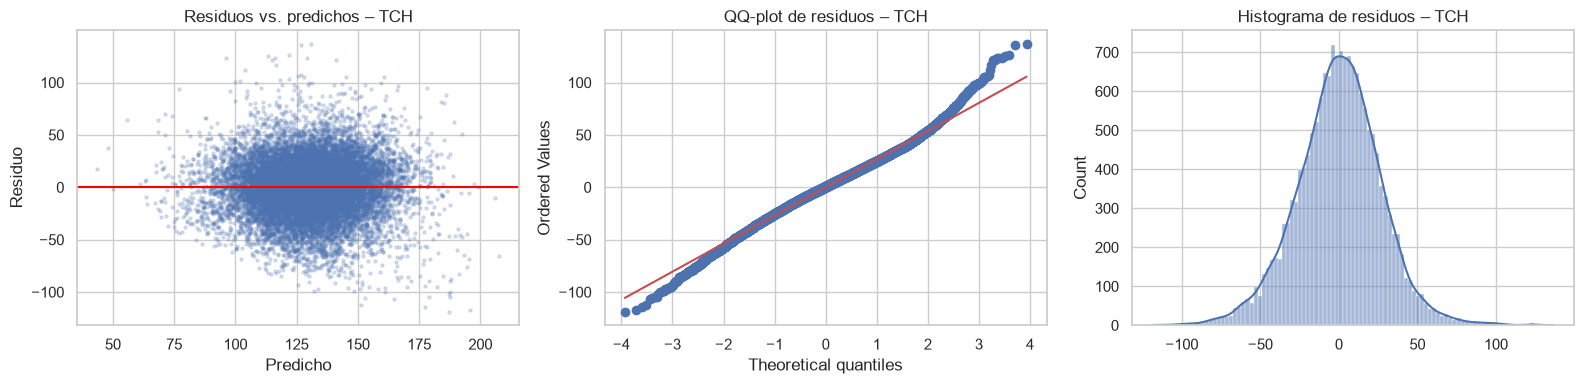

Breusch-Pagan p-valor = 6.4e-160 (< 0.05 = heterocedasticidad)


In [34]:
def ajustar_ols(X_train, X_test, y_train, y_test, objetivo):
    prep = crear_preprocesamiento(X_train)
    Xtr = sm.add_constant(pd.DataFrame(prep.fit_transform(X_train),
                                       columns=prep.get_feature_names_out(), index=X_train.index))
    Xte = sm.add_constant(pd.DataFrame(prep.transform(X_test),
                                       columns=prep.get_feature_names_out(), index=X_test.index),
                          has_constant="add")
    ols = sm.OLS(y_train, Xtr).fit()

    print(f"{objetivo}: R² ajustado (train) = {ols.rsquared_adj:.3f} | p-valor prueba F = {ols.f_pvalue:.1e}")
    numericas = X_train.select_dtypes("number").columns
    display(pd.DataFrame({"Coeficiente": ols.params[numericas], "p-valor": ols.pvalues[numericas]})
            .sort_values("p-valor").round(4))
    dummies = ols.pvalues.drop(["const", *numericas])
    print(f"Categorías (dummies) significativas (p < 0.05): {(dummies < 0.05).sum()} de {len(dummies)}")

    # Supuestos del modelo
    residuos = ols.resid
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    axes[0].scatter(ols.fittedvalues, residuos, alpha=0.2, s=5)
    axes[0].axhline(0, color="red")
    axes[0].set(title=f"Residuos vs. predichos – {objetivo}", xlabel="Predicho", ylabel="Residuo")
    stats.probplot(residuos, plot=axes[1])
    axes[1].set_title(f"QQ-plot de residuos – {objetivo}")
    sns.histplot(residuos, kde=True, ax=axes[2])
    axes[2].set_title(f"Histograma de residuos – {objetivo}")
    plt.tight_layout()
    plt.show()
    print(f"Breusch-Pagan p-valor = {het_breuschpagan(residuos, Xtr)[1]:.1e} (< 0.05 = heterocedasticidad)")

    # Validación cruzada (5 vueltas) sobre el entrenamiento con el modelo lineal equivalente
    pipeline = Pipeline([("prep", crear_preprocesamiento(X_train)), ("modelo", LinearRegression())])
    rmse_cv = -cross_val_score(pipeline, X_train, y_train, cv=5,
                               scoring="neg_root_mean_squared_error").mean()
    return metricas(y_test, ols.predict(Xte), "Regresión lineal (OLS)", objetivo, rmse_cv)


columnas_lineal_tch = predictores_tch_lineal + ["sin_registro_lluvia"]
resultados.append(ajustar_ols(X_train_tch[columnas_lineal_tch], X_test_tch[columnas_lineal_tch],
                              y_train_tch, y_test_tch, "TCH"))

**Interpretación (TCH):**
- El modelo es significativo en conjunto (prueba F con p < 0,001), pero solo explica el **30 % de la variabilidad** (R² ajustado = 0,296).
- **Coeficientes significativos y coherentes con la Tarea 1:**
  - **Edad de cosecha (+8,5 t/ha** por cada desviación estándar): más tiempo en el campo, más biomasa. Es la variable de mayor magnitud.
  - **Número de corte (−5,0 t/ha):** cada soca rinde menos que la anterior.
  - **Riego (+2,6 t/ha):** más agua aplicada, más rendimiento.
  - **Distancia al ingenio (−3,4 t/ha):** las haciendas lejanas rinden menos, probablemente por diferencias de manejo y ubicación.
  - **Sin lluvia registrada (−3,5 t/ha):** estas suertes tienen un rendimiento algo menor que el promedio.
- 52 de las 67 categorías (variedades, suelos, zonas…) son significativas, así que el tipo de variedad y de suelo sí importa.
- **Supuestos:**
  - **Linealidad:** los residuos se reparten alrededor de 0 sin una forma marcada.
  - **Normalidad:** se cumple en el centro (histograma simétrico), pero el QQ-plot muestra colas más pesadas.
  - **Homocedasticidad:** **no se cumple** (Breusch-Pagan p < 0,001); la varianza del error no es constante.

  Esto no sesga las predicciones, pero hace que los p-valores sean menos confiables. Es otra razón para probar modelos que no dependen de estos supuestos.

%Sac.Caña: R² ajustado (train) = 0.294 | p-valor prueba F = 0.0e+00


,Coeficiente,p-valor
Lluvias (2 Meses Ant.),-0.2564,0.0000
Semanas mad.,0.2294,0.0000
Mes Corte,0.0936,0.0000
Dosis Madurante,0.1517,0.0000
sin_registro_lluvia,0.0672,0.0000
M3 Riego,0.0214,0.0202
Lluvias Ciclo,0.0243,0.0272
Cod.Estado #,0.0178,0.0959
Edad Ult Cos,-0.0139,0.1197


Categorías (dummies) significativas (p < 0.05): 20 de 67


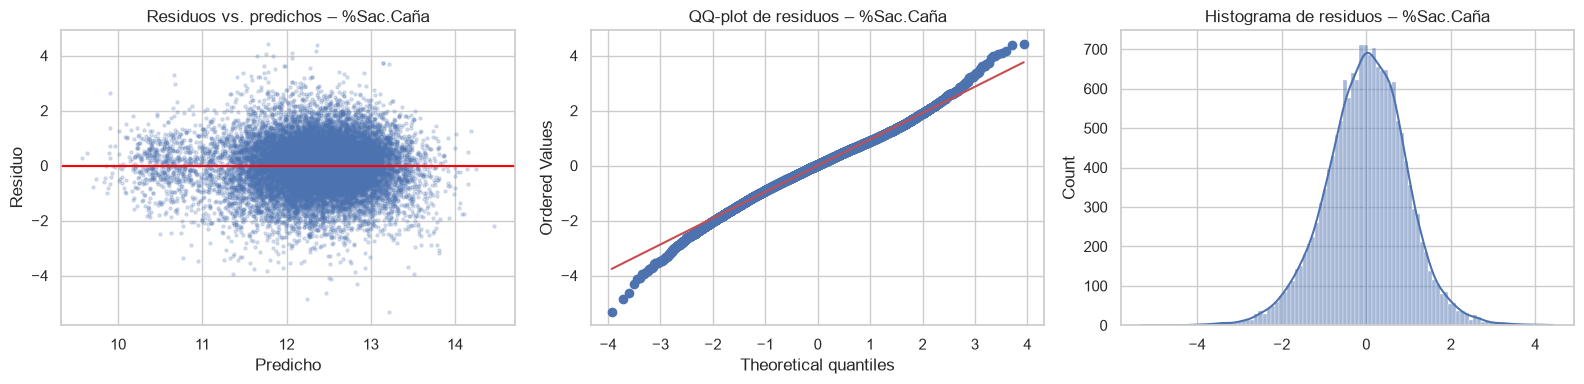

Breusch-Pagan p-valor = 1.7e-78 (< 0.05 = heterocedasticidad)


In [35]:
columnas_lineal_sac = predictores_sacarosa_lineal + ["sin_registro_lluvia"]
resultados.append(ajustar_ols(X_train_sac[columnas_lineal_sac], X_test_sac[columnas_lineal_sac],
                              y_train_sac, y_test_sac, "%Sac.Caña"))

**Interpretación (%Sac.Caña):**
- R² ajustado de 0,294.
- **Las variables de mayor efecto son exactamente las de maduración que señala la Tarea 1:**
  - **Lluvia en los 2 meses previos (−0,26 puntos):** la lluvia antes del corte diluye la sacarosa.
  - **Semanas de maduración (+0,23)** y **dosis de madurante (+0,15):** el madurante aumenta la concentración de azúcar.
  - **Mes de corte (+0,09):** hay un efecto de temporada.
- La edad de cosecha y el número de corte **no son significativos** (p > 0,05). Influyen en las toneladas, pero no en la concentración de azúcar.
- **Supuestos:** igual que en TCH, los residuos son simétricos pero con colas pesadas, y hay heterocedasticidad (Breusch-Pagan p < 0,001).

### 3.4 Modelos avanzados: Random Forest y XGBoost

Estos modelos de árboles pueden captar **relaciones no lineales e interacciones** entre variables (por ejemplo, lluvia × suelo × variedad). En la Tarea 2 se vio que varias relaciones son curvas: la edad de cosecha, las semanas de maduración y el número de corte. Estos modelos usan la lista completa de predictores, porque la multicolinealidad no los afecta.

Los hiperparámetros se eligen con **`GridSearchCV` con validación cruzada de 5 vueltas, solo sobre el entrenamiento**. El conjunto de prueba se usa una única vez, al final.

In [36]:
modelos = {
    "Random Forest": (RandomForestRegressor(random_state=42, n_jobs=-1),
                      {"modelo__n_estimators": [200],
                       "modelo__max_depth": [10, 20, None],
                       "modelo__min_samples_leaf": [1, 5]}),
    "XGBoost": (XGBRegressor(random_state=42, n_jobs=-1),
                {"modelo__n_estimators": [300, 600],
                 "modelo__max_depth": [4, 6],
                 "modelo__learning_rate": [0.05, 0.1]})
}

datos_objetivos = {"TCH": (X_train_tch, X_test_tch, y_train_tch, y_test_tch),
                   "%Sac.Caña": (X_train_sac, X_test_sac, y_train_sac, y_test_sac)}
mejores_modelos = {}

for objetivo, (X_tr, X_te, y_tr, y_te) in datos_objetivos.items():
    for nombre, (estimador, grilla) in modelos.items():
        pipeline = Pipeline([("prep", crear_preprocesamiento(X_tr)), ("modelo", estimador)])
        busqueda = GridSearchCV(pipeline, grilla, cv=5, scoring="neg_root_mean_squared_error")
        busqueda.fit(X_tr, y_tr)

        mejores_modelos[(objetivo, nombre)] = busqueda.best_estimator_
        resultados.append(metricas(y_te, busqueda.predict(X_te), nombre, objetivo, -busqueda.best_score_))
        parametros = {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()}
        print(f"{objetivo} – {nombre}: {parametros}")

TCH – Random Forest: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 200}


TCH – XGBoost: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 600}


%Sac.Caña – Random Forest: {'max_depth': None, 'min_samples_leaf': 5, 'n_estimators': 200}


%Sac.Caña – XGBoost: {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 600}


### 3.5 Comparación de modelos de regresión

In [37]:
tabla_regresion = pd.DataFrame(resultados).round(3)
display(tabla_regresion.sort_values(["Objetivo", "RMSE (test)"]))

,Objetivo,Modelo,RMSE CV (train),R² (test),RMSE (test),MAE (test)
5,%Sac.Caña,XGBoost,0.840,0.454,0.826,0.637
4,%Sac.Caña,Random Forest,0.845,0.453,0.827,0.639
1,%Sac.Caña,Regresión lineal (OLS),0.963,0.283,0.947,0.742
3,TCH,XGBoost,22.833,0.526,22.204,16.490
2,TCH,Random Forest,24.022,0.471,23.440,17.498
0,TCH,Regresión lineal (OLS),27.077,0.296,27.053,20.822


**Interpretación:**
- **XGBoost es el mejor modelo para los dos objetivos:**
  - **TCH:** R² de 0,30 → **0,53**, RMSE de 27,1 → **22,2 t/ha** (18 % menos error que la regresión lineal). Random Forest queda en medio (R² = 0,47).
  - **%Sac.Caña:** R² de 0,28 → **0,45**, RMSE de 0,95 → **0,83 puntos**. Random Forest y XGBoost quedan prácticamente empatados.
- **No hay sobreajuste:** el RMSE de la validación cruzada (entrenamiento) es muy parecido al de prueba en todos los modelos.
- La mejora de los árboles confirma lo visto en la Tarea 2: las relaciones son **no lineales** (meseta en la edad de cosecha y en las semanas de maduración, caída en las socas) y hay **interacciones** entre variedad, suelo y ubicación que la regresión lineal no capta.
- Aun así, cerca de la mitad de la variabilidad sigue sin explicarse. Faltan variables que no están en los datos, como la fertilización real, el clima completo o las plagas (ver trabajo futuro).

### 3.6 Importancia de variables y valores reales vs. predichos

Para el mejor modelo de árboles de cada objetivo se calcula la **importancia por permutación** sobre el conjunto de prueba. Se desordena una variable a la vez y se mide cuánto empeora el RMSE: cuanto más empeora, más depende el modelo de esa variable. A diferencia de la importancia interna de los árboles, este método mide cada variable original completa (por ejemplo, `Variedad` y no cada una de sus dummies).

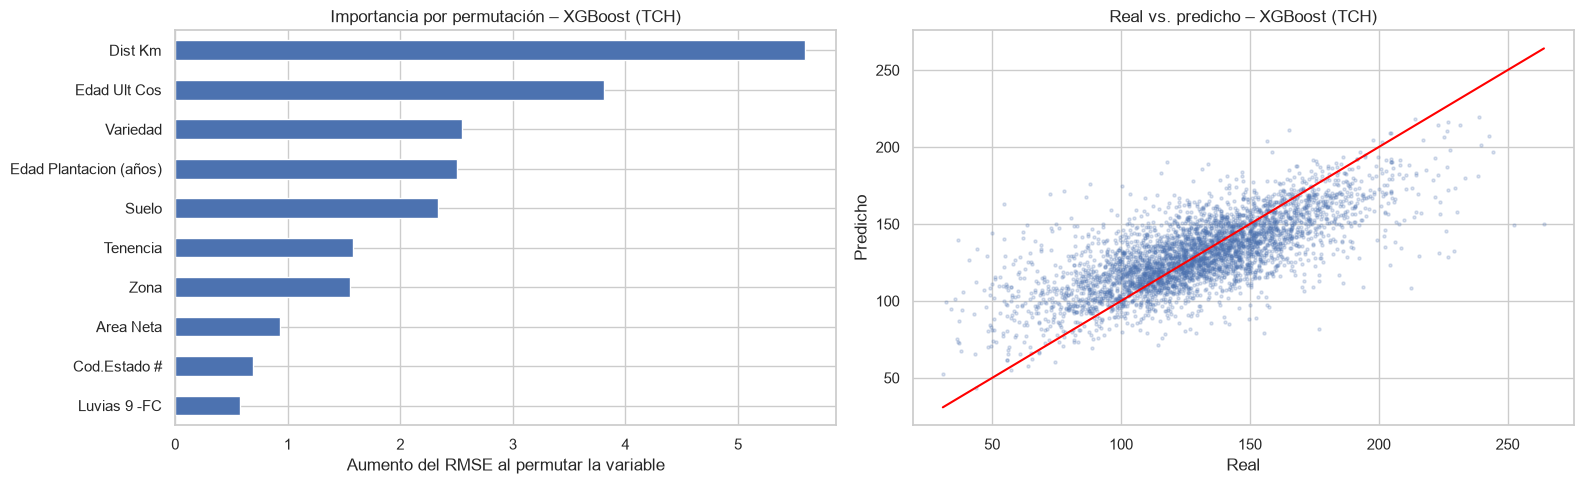

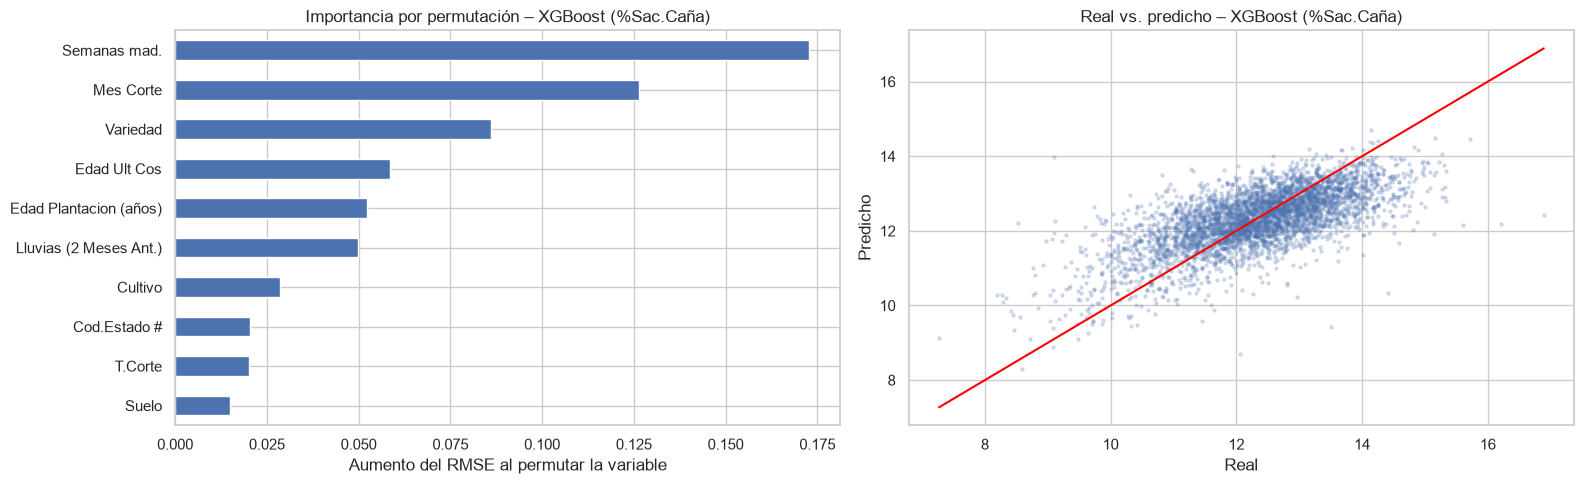

In [38]:
for objetivo, (X_tr, X_te, y_tr, y_te) in datos_objetivos.items():
    candidatos = tabla_regresion[(tabla_regresion["Objetivo"] == objetivo)
                                 & (tabla_regresion["Modelo"] != "Regresión lineal (OLS)")]
    nombre = candidatos.sort_values("RMSE (test)").iloc[0]["Modelo"]
    modelo = mejores_modelos[(objetivo, nombre)]

    permutacion = permutation_importance(modelo, X_te, y_te, n_repeats=5, random_state=42,
                                         scoring="neg_root_mean_squared_error")
    importancia = pd.Series(permutacion.importances_mean, index=X_te.columns).sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(16, 5))
    importancia.tail(10).plot(kind="barh", ax=axes[0])
    axes[0].set(title=f"Importancia por permutación – {nombre} ({objetivo})",
                xlabel="Aumento del RMSE al permutar la variable")

    predicho = modelo.predict(X_te)
    axes[1].scatter(y_te, predicho, alpha=0.2, s=5)
    limites = [y_te.min(), y_te.max()]
    axes[1].plot(limites, limites, color="red")
    axes[1].set(title=f"Real vs. predicho – {nombre} ({objetivo})", xlabel="Real", ylabel="Predicho")
    plt.tight_layout()
    plt.show()

**Interpretación:**
- **TCH:**
  - Las variables más influyentes son **Dist Km** y la **edad de cosecha**, seguidas por variedad, edad de la plantación y suelo.
  - `Dist Km` es casi constante dentro de cada hacienda, así que probablemente funciona como un *indicador de la hacienda*: resume su ubicación, sus prácticas de manejo y sus condiciones locales.
  - Variedad y suelo confirman lo que dice la Tarea 1.
- **%Sac.Caña:**
  - Domina **Semanas mad.**, seguida por **Mes Corte** (estacionalidad), **Variedad** y la edad de cosecha. Las lluvias de los 2 meses previos también aparecen entre las más importantes.
  - Esto coincide con la literatura: la sacarosa depende sobre todo de la **maduración** y del **clima previo a la cosecha**.
- **Real vs. predicho:** los puntos siguen la diagonal. Sin embargo, en ambos objetivos el modelo **sobreestima los valores bajos y subestima los altos**, es decir, tiende a predecir cerca del promedio. Es típico cuando faltan variables que expliquen los casos extremos.

### 3.7 Clasificación: preparación de los datos

Se usa el dataset IPSA con las clases creadas en 2.16 (`nivel_TCH` y `nivel_sacarosa`: Bajo, Medio, Alto). Se aplica la misma metodología que en la regresión:
- División 80/20 **estratificada**, para que las tres clases tengan la misma proporción en entrenamiento y prueba.
- Preprocesamiento dentro de un `Pipeline`. `grupo_tenencia` se trata como categórica, y se agrega el indicador `sin_registro_lluvia`.
- Hiperparámetros elegidos con `GridSearchCV(cv=5)` sobre el entrenamiento.

Como las clases están balanceadas, un modelo que adivinara al azar acertaría el **33 %**. Esa es la referencia mínima.

In [39]:
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             cohen_kappa_score, ConfusionMatrixDisplay)

# penalty="elasticnet" + l1_ratio funciona en versiones nuevas y antiguas de sklearn
warnings.filterwarnings("ignore", message=".*'penalty' was deprecated.*")


def dividir_clasificacion(df, objetivo):
    datos = df.copy()
    datos["sin_registro_lluvia"] = datos["lluvias"].isna().astype(int)
    datos["grupo_tenencia"] = datos["grupo_tenencia"].astype(str)
    X = datos[predictores_ipsa + ["sin_registro_lluvia"]]
    y = datos[objetivo].cat.codes   # 0 = Bajo, 1 = Medio, 2 = Alto
    return train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)


def metricas_clasificacion(y_real, y_pred, modelo, objetivo, accuracy_cv):
    return {"Objetivo": objetivo, "Modelo": modelo,
            "Accuracy CV (train)": accuracy_cv,
            "Accuracy (test)": accuracy_score(y_real, y_pred),
            "Precision (macro)": precision_score(y_real, y_pred, average="macro"),
            "Recall (macro)": recall_score(y_real, y_pred, average="macro"),
            "F1 (macro)": f1_score(y_real, y_pred, average="macro"),
            "Kappa": cohen_kappa_score(y_real, y_pred)}


datos_clasificacion = {"nivel_TCH": dividir_clasificacion(ipsa_limpio, "nivel_TCH"),
                       "nivel_sacarosa": dividir_clasificacion(ipsa_limpio, "nivel_sacarosa")}

X_tr, X_te, y_tr, y_te = datos_clasificacion["nivel_TCH"]
print("Entrenamiento:", X_tr.shape, "| Prueba:", X_te.shape)
print("Proporción de clases en prueba:", y_te.value_counts(normalize=True).sort_index().round(2).tolist())

resultados_clasificacion = []
mejores_clasificadores = {}


def entrenar_clasificador(nombre, estimador, grilla):
    for objetivo, (X_tr, X_te, y_tr, y_te) in datos_clasificacion.items():
        pipeline = Pipeline([("prep", crear_preprocesamiento(X_tr)), ("modelo", estimador)])
        busqueda = GridSearchCV(pipeline, grilla, cv=5, scoring="accuracy")
        busqueda.fit(X_tr, y_tr)
        mejores_clasificadores[(objetivo, nombre)] = busqueda
        resultados_clasificacion.append(metricas_clasificacion(
            y_te, busqueda.predict(X_te), nombre, objetivo, busqueda.best_score_))
        parametros = {k.replace("modelo__", ""): v for k, v in busqueda.best_params_.items()}
        print(f"{objetivo} – {nombre}: {parametros}")

Entrenamiento: (1748, 9) | Prueba: (438, 9)
Proporción de clases en prueba: [0.34, 0.32, 0.33]


### 3.8 Modelo de referencia: regresión logística multinomial (L1 y L2)

La regresión logística multinomial estima la probabilidad de cada una de las 3 clases. Se comparan dos tipos de regularización:
- **L2 (Ridge):** reduce todos los coeficientes, pero no elimina ninguno.
- **L1 (Lasso):** puede llevar coeficientes **exactamente a 0**, es decir, hace selección de variables.

`C` controla la fuerza de la regularización: un `C` más pequeño significa más regularización.

In [40]:
entrenar_clasificador(
    "Regresión logística",
    LogisticRegression(penalty="elasticnet", solver="saga", max_iter=5000),
    {"modelo__l1_ratio": [0, 1],            # 0 = L2, 1 = L1
     "modelo__C": [0.01, 0.1, 1, 10]})

# Coeficientes del modelo con L1 (C = 0.1) para ver qué variables elimina
for objetivo, (X_tr, X_te, y_tr, y_te) in datos_clasificacion.items():
    modelo_l1 = Pipeline([("prep", crear_preprocesamiento(X_tr)),
                          ("modelo", LogisticRegression(penalty="elasticnet", l1_ratio=1, C=0.1,
                                                        solver="saga", max_iter=5000))])
    modelo_l1.fit(X_tr, y_tr)
    coeficientes = pd.DataFrame(modelo_l1["modelo"].coef_.T,
                                index=modelo_l1["prep"].get_feature_names_out(),
                                columns=["Bajo", "Medio", "Alto"]).round(3)
    print(f"\n{objetivo} – coeficientes con L1 (C = 0.1):")
    display(coeficientes)
    eliminadas = coeficientes.index[(coeficientes == 0).all(axis=1)].tolist()
    print("Variables eliminadas por L1:", eliminadas)

nivel_TCH – Regresión logística: {'C': 10, 'l1_ratio': 1}


nivel_sacarosa – Regresión logística: {'C': 0.1, 'l1_ratio': 1}

nivel_TCH – coeficientes con L1 (C = 0.1):


,Bajo,Medio,Alto
edad,-0.055,0.000,0.241
cortes,0.142,0.000,-0.436
lluvias,0.000,-0.081,0.011
pct_diatrea,-0.208,0.016,0.000
dosismad,-0.040,0.000,0.141
semsmad,0.127,0.000,0.000
mes,-0.036,0.000,0.000
sin_registro_lluvia,0.000,-0.100,0.000
grupo_tenencia_2,0.000,0.000,0.000
grupo_tenencia_3,-0.340,0.000,0.287


Variables eliminadas por L1: ['grupo_tenencia_2']

nivel_sacarosa – coeficientes con L1 (C = 0.1):


,Bajo,Medio,Alto
edad,0.000,0.000,0.000
cortes,0.000,0.000,-0.076
lluvias,0.520,0.000,-0.418
pct_diatrea,0.133,0.000,-0.014
dosismad,0.000,0.000,0.000
semsmad,-0.232,0.000,0.405
mes,0.000,0.000,0.159
sin_registro_lluvia,0.158,0.000,-0.047
grupo_tenencia_2,0.000,-0.049,0.108
grupo_tenencia_3,0.000,0.000,0.000


Variables eliminadas por L1: ['edad', 'dosismad', 'grupo_tenencia_3']


**Interpretación:**
- En los dos objetivos, la validación cruzada eligió **L1** (`l1_ratio = 1`). La selección de variables ayuda más que solo reducir los coeficientes.
- **nivel_TCH:**
  - Más **cortes** bajan la probabilidad de la clase Alta (−0,44) y suben la de la Baja (+0,14). Es el efecto de las socas que ya se vio en la regresión.
  - Más **edad** y **dosis de madurante** favorecen la clase Alta.
  - La **diatrea** se asocia con salir de la clase Baja, un efecto contraintuitivo y pequeño.
  - L1 eliminó `grupo_tenencia_2`.
- **nivel_sacarosa:**
  - Las variables decisivas son las de maduración y clima. Más **lluvias** empujan a la clase Baja (+0,52) y alejan de la Alta (−0,42). Más **semanas de maduración** favorecen la Alta (+0,41).
  - L1 eliminó por completo la **edad**, la **dosis de madurante** y `grupo_tenencia_3`. Con las semanas de maduración y la lluvia, estas variables no aportan información adicional.
- La columna "Medio" casi no tiene coeficientes distintos de 0. La clase intermedia no tiene un perfil propio: queda definida por exclusión de las otras dos.

### 3.9 K-Vecinos Más Cercanos (KNN)

KNN clasifica cada suerte según la clase más común entre sus `k` vecinos más parecidos. Como se basa en distancias, el escalado de las variables (incluido en el Pipeline) es indispensable. Se busca el mejor `k` entre 1 y 59 con validación cruzada.

nivel_TCH – KNN: {'n_neighbors': 1}


nivel_sacarosa – KNN: {'n_neighbors': 39}


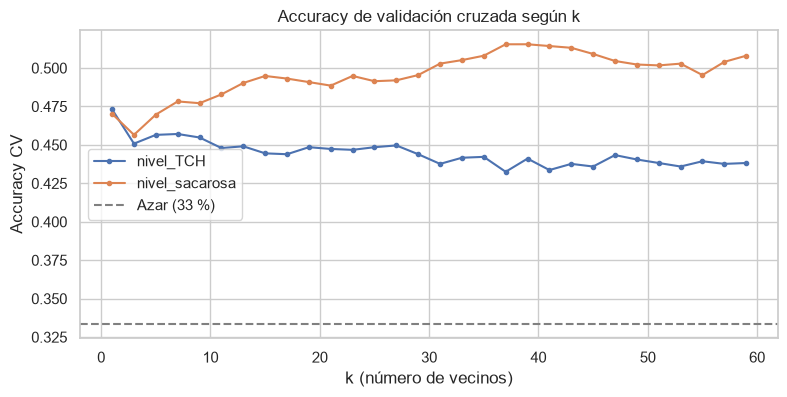

In [41]:
valores_k = list(range(1, 60, 2))
entrenar_clasificador("KNN", KNeighborsClassifier(), {"modelo__n_neighbors": valores_k})

fig, ax = plt.subplots(figsize=(9, 4))
for objetivo in datos_clasificacion:
    cv = mejores_clasificadores[(objetivo, "KNN")].cv_results_
    ax.plot(valores_k, cv["mean_test_score"], marker="o", markersize=3, label=objetivo)
ax.axhline(1 / 3, color="gray", linestyle="--", label="Azar (33 %)")
ax.set(title="Accuracy de validación cruzada según k", xlabel="k (número de vecinos)", ylabel="Accuracy CV")
ax.legend()
plt.show()

**Interpretación:**
- **nivel_sacarosa:** la accuracy mejora a medida que crece k, hasta un máximo cerca de **k = 39**. Promediar muchos vecinos suaviza el ruido, lo que indica una señal débil pero consistente.
- **nivel_TCH:** el mejor valor es **k = 1**. Esto es poco común y tiene una explicación en los datos: el 62 % de los registros comparte hacienda y periodo con otros lotes (mismas lluvias, mismo mes). Además, dentro de una misma hacienda y periodo el TCH varía la mitad que en general. Con k = 1, el modelo encuentra un "lote hermano" de la misma hacienda y copia su clase, es decir, **reconoce la hacienda** más que aprender una relación agronómica. Es una limitación de la validación aleatoria. Una validación agrupada por hacienda (`GroupKFold`) sería más estricta (trabajo futuro).
- Todos los valores de k superan claramente el azar (33 %).

### 3.10 Modelos avanzados: Random Forest y XGBoost

Igual que en la regresión, los modelos de árboles pueden captar relaciones no lineales e interacciones entre variables, como edad × semanas de maduración × lluvia.

In [42]:
entrenar_clasificador(
    "Random Forest",
    RandomForestClassifier(n_estimators=300, random_state=42, n_jobs=-1),
    {"modelo__max_depth": [5, 10, None], "modelo__min_samples_leaf": [1, 5]})

entrenar_clasificador(
    "XGBoost",
    XGBClassifier(random_state=42, n_jobs=-1),
    {"modelo__n_estimators": [200, 400], "modelo__max_depth": [3, 5],
     "modelo__learning_rate": [0.05, 0.1]})

nivel_TCH – Random Forest: {'max_depth': None, 'min_samples_leaf': 1}


nivel_sacarosa – Random Forest: {'max_depth': 5, 'min_samples_leaf': 1}


nivel_TCH – XGBoost: {'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 400}


nivel_sacarosa – XGBoost: {'learning_rate': 0.05, 'max_depth': 5, 'n_estimators': 200}


### 3.11 Comparación de modelos de clasificación y matrices de confusión

- **Precision, Recall y F1** se promedian entre las tres clases (macro), porque todas tienen la misma importancia.
- **Kappa** mide cuánto mejor es el modelo que el azar: 0 = igual que el azar, 1 = perfecto.

,Objetivo,Modelo,Accuracy CV (train),Accuracy (test),Precision (macro),Recall (macro),F1 (macro),Kappa
4,nivel_TCH,Random Forest,0.513,0.495,0.493,0.493,0.491,0.242
2,nivel_TCH,KNN,0.473,0.450,0.453,0.449,0.450,0.175
6,nivel_TCH,XGBoost,0.495,0.441,0.438,0.439,0.438,0.160
0,nivel_TCH,Regresión logística,0.475,0.388,0.387,0.385,0.374,0.078
7,nivel_sacarosa,XGBoost,0.522,0.523,0.514,0.520,0.516,0.283
5,nivel_sacarosa,Random Forest,0.525,0.502,0.475,0.497,0.475,0.250
3,nivel_sacarosa,KNN,0.515,0.445,0.430,0.441,0.433,0.165
1,nivel_sacarosa,Regresión logística,0.474,0.443,0.426,0.439,0.420,0.160


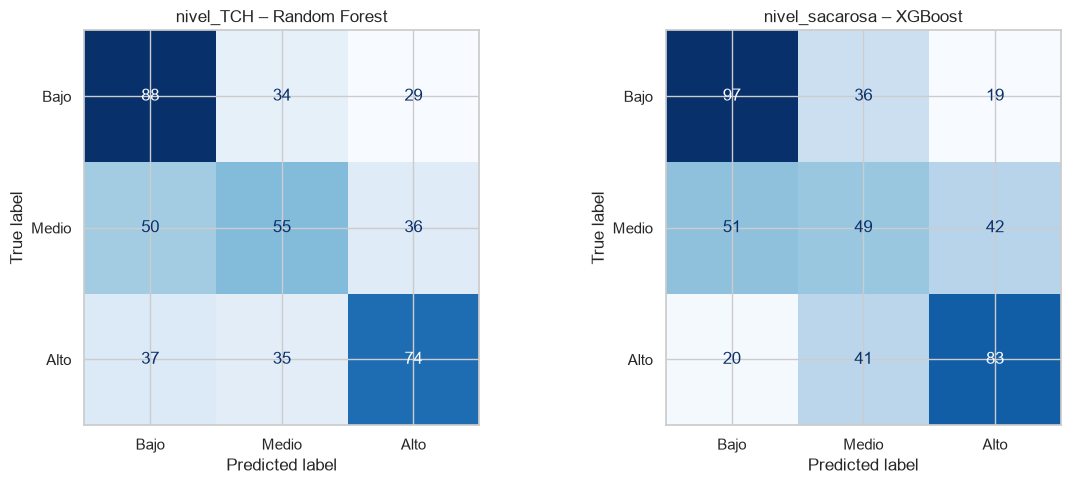

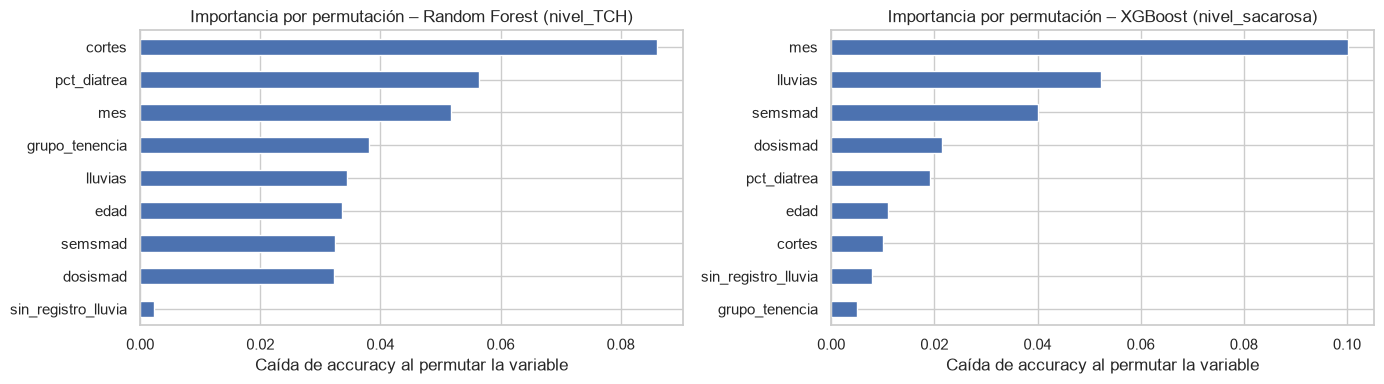

In [43]:
tabla_clasificacion = pd.DataFrame(resultados_clasificacion).round(3)
display(tabla_clasificacion.sort_values(["Objetivo", "Accuracy (test)"], ascending=[True, False]))

# Matriz de confusión del mejor modelo de cada objetivo
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, objetivo in zip(axes, datos_clasificacion):
    X_tr, X_te, y_tr, y_te = datos_clasificacion[objetivo]
    filas = tabla_clasificacion[tabla_clasificacion["Objetivo"] == objetivo]
    nombre = filas.sort_values("Accuracy (test)").iloc[-1]["Modelo"]
    ConfusionMatrixDisplay.from_estimator(mejores_clasificadores[(objetivo, nombre)], X_te, y_te,
                                          display_labels=["Bajo", "Medio", "Alto"],
                                          cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(f"{objetivo} – {nombre}")
plt.tight_layout()
plt.show()

# Importancia por permutación del mejor modelo de cada objetivo
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, objetivo in zip(axes, datos_clasificacion):
    X_tr, X_te, y_tr, y_te = datos_clasificacion[objetivo]
    filas = tabla_clasificacion[tabla_clasificacion["Objetivo"] == objetivo]
    nombre = filas.sort_values("Accuracy (test)").iloc[-1]["Modelo"]
    permutacion = permutation_importance(mejores_clasificadores[(objetivo, nombre)], X_te, y_te,
                                         n_repeats=10, random_state=42, scoring="accuracy")
    pd.Series(permutacion.importances_mean, index=X_te.columns).sort_values().plot(kind="barh", ax=ax)
    ax.set(title=f"Importancia por permutación – {nombre} ({objetivo})",
           xlabel="Caída de accuracy al permutar la variable")
plt.tight_layout()
plt.show()

**Interpretación:**
- **Mejores modelos:**
  - **nivel_TCH:** Random Forest, con accuracy de **49,5 %**, F1 de 0,49 y Kappa de 0,24.
  - **nivel_sacarosa:** XGBoost, con accuracy de **52,3 %**, F1 de 0,52 y Kappa de 0,28.
- Ambos superan claramente el azar (33 %) y a la regresión logística (39 % y 44 %), lo que confirma relaciones no lineales también en la clasificación. Kappa entre 0,2 y 0,3 indica un acuerdo **aceptable** por encima del azar.
- **Matrices de confusión:** como se esperaba, la clase **Medio es la más difícil**. En TCH se acierta en 55 de 141 casos, y en sacarosa en 49 de 142. Las clases extremas se reconocen mejor (TCH Bajo 88/151 y Alto 74/146; sacarosa Bajo 97/152 y Alto 83/144). En sacarosa, la confusión grave (Bajo ↔ Alto) es poco frecuente (19 y 20 casos).
- **Importancia de variables:**
  - **nivel_TCH:** dominan los **cortes**, seguidos por la diatrea, el mes y el grupo de tenencia. Coincide con la Tarea 1: las socas sucesivas pierden productividad.
  - **nivel_sacarosa:** dominan el **mes** (estacionalidad), las **lluvias** y las **semanas de maduración**. Es el mismo patrón de la regresión del histórico: la sacarosa depende del clima previo a la cosecha y de la maduración.
- El desempeño es moderado por las mismas razones que en la regresión, y en IPSA se suman otras: tiene menos datos (2 186), no tiene variedad (todo es CC01-1940) ni suelo, la clase Medio es angosta (20 t/ha y 0,7 puntos de sacarosa) y el 31 % de las lluvias no está registrado.

## Tabla comparativa final de modelos

### Regresión (dataset Histórico, conjunto de prueba = 20 %)

| Objetivo | Modelo | Hiperparámetros (GridSearchCV, cv=5) | RMSE CV (train) | R² (test) | RMSE (test) | MAE (test) |
|---|---|---|---|---|---|---|
| TCH | Regresión lineal (OLS) | — | 27,08 | 0,296 | 27,05 t/ha | 20,82 t/ha |
| TCH | Random Forest | 200 árboles, max_depth = None, min_samples_leaf = 1 | 24,02 | 0,471 | 23,44 t/ha | 17,50 t/ha |
| TCH | **XGBoost** | 600 árboles, max_depth = 6, learning_rate = 0,1 | 22,83 | **0,526** | **22,20 t/ha** | **16,49 t/ha** |
| %Sac.Caña | Regresión lineal (OLS) | — | 0,963 | 0,283 | 0,947 | 0,742 |
| %Sac.Caña | Random Forest | 200 árboles, max_depth = None, min_samples_leaf = 5 | 0,845 | 0,453 | 0,827 | 0,639 |
| %Sac.Caña | **XGBoost** | 600 árboles, max_depth = 6, learning_rate = 0,05 | 0,840 | **0,454** | **0,826** | **0,637** |

### Clasificación (dataset IPSA, conjunto de prueba = 20 %, azar = 33 %)

| Objetivo | Modelo | Hiperparámetros (GridSearchCV, cv=5) | Accuracy CV (train) | Accuracy (test) | Precision (macro) | Recall (macro) | F1 (macro) | Kappa |
|---|---|---|---|---|---|---|---|---|
| nivel_TCH | Regresión logística | L1, C = 10 | 0,475 | 0,388 | 0,387 | 0,385 | 0,374 | 0,078 |
| nivel_TCH | KNN | k = 1 | 0,473 | 0,450 | 0,453 | 0,449 | 0,450 | 0,175 |
| nivel_TCH | **Random Forest** | max_depth = None, min_samples_leaf = 1 | 0,513 | **0,495** | **0,493** | **0,493** | **0,491** | **0,242** |
| nivel_TCH | XGBoost | 400 árboles, max_depth = 5, learning_rate = 0,1 | 0,495 | 0,441 | 0,438 | 0,439 | 0,438 | 0,160 |
| nivel_sacarosa | Regresión logística | L1, C = 0,1 | 0,474 | 0,443 | 0,426 | 0,439 | 0,420 | 0,160 |
| nivel_sacarosa | KNN | k = 39 | 0,515 | 0,445 | 0,430 | 0,441 | 0,433 | 0,165 |
| nivel_sacarosa | Random Forest | max_depth = 5, min_samples_leaf = 1 | 0,525 | 0,502 | 0,475 | 0,497 | 0,475 | 0,250 |
| nivel_sacarosa | **XGBoost** | 200 árboles, max_depth = 5, learning_rate = 0,05 | 0,522 | **0,523** | **0,514** | **0,520** | **0,516** | **0,283** |

### Conclusiones de la comparación
- **Los modelos de árboles superan a los de referencia en las 4 tareas.**
  - En regresión, XGBoost reduce el RMSE un 18 % (TCH) y un 13 % (%Sac.Caña) frente a la regresión lineal.
  - En clasificación, el mejor modelo de árboles supera a la regresión logística en 11 puntos de accuracy para TCH y en 8 puntos para sacarosa.
  - Esto confirma que las relaciones entre manejo, clima y rendimiento son **no lineales**.
- **Las variables más influyentes son coherentes con la Tarea 1:**
  - **TCH:** edad de cosecha, número de cortes, variedad y ubicación.
  - **Sacarosa:** semanas de maduración, lluvias previas a la cosecha y estacionalidad (mes).
- **El desempeño es moderado** (R² ≈ 0,5; accuracy ≈ 50 %) por la información ausente en los datos (lluvias sin registro, fertilización, clima y plagas casi vacíos), no por el modelo. Incorporar datos satelitales, de estaciones climáticas y de fertilización es la principal línea de mejora.